In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

NPZ_FILE = "Concrete_different_times1.npz"

npz = np.load(NPZ_FILE, allow_pickle=True)
data = npz["data"].item()
npz.close()


durations = [1.0, 1.5, 2.0, 2.5, 3.0]

duration_labels = {
    1.0: "1 s",
    1.5: "1.5 s",
    2.0: "2 s",
    2.5: "2.5 s",
    3.0: "3 s",
}


category_keys = {
    "Dry concrete": {
        1.0: "Concrete_1s",
        1.5: "Concrete_1_5s",
        2.0: "Concrete_2s",
        2.5: "Concrete_2_5s",
        3.0: "Concrete_3s",
    },

    "Wet concrete": {
        1.0: "Concrete_wet_1s",
        1.5: "Concrete_wet_1_5s",
        2.0: "Concrete_wet_2s",
        2.5: "Concrete_wet_2_5s",
        3.0: "Concrete_wet_3s",
    },

    "Soap": {
        1.0: "Soap_1s",
        1.5: "Soap_1_5s",
        2.0: "Soap_2s",
        2.5: "Soap_2_5s",
        3.0: "Soap_3s",
    },
}


surface_colors = {
    "Dry concrete": "#333333",
    "Wet concrete": "#1F77B4",
    "Soap": "#D62728",
}


duration_colors = {
    1.0: "#000000",
    1.5: "#1F77B4",
    2.0: "#2CA02C",
    2.5: "#E6B800",
    3.0: "#D62728",
}


def get_values(category, key):
    values = np.asarray(
        data[category][key],
        dtype=float,
    ).ravel()

    return values[np.isfinite(values)]

In [2]:
def plot_metric_comparison(metric, ylabel, title):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
        sharey=True,
    )

    for ax, direction, direction_title in zip(
        axes,
        ["down", "up"],
        ["Down segments (FG +vx)", "Up segments (FG −vx)"],
    ):
        for surface, duration_map in category_keys.items():

            medians = []
            q25_values = []
            q75_values = []

            for duration in durations:

                category = duration_map[duration]

                values = get_values(
                    category,
                    f"{direction}_{metric}",
                )

                medians.append(np.median(values))
                q25_values.append(np.percentile(values, 25))
                q75_values.append(np.percentile(values, 75))

            medians = np.asarray(medians)
            q25_values = np.asarray(q25_values)
            q75_values = np.asarray(q75_values)

            error = np.vstack([
                medians - q25_values,
                q75_values - medians,
            ])

            ax.errorbar(
                durations,
                medians,
                yerr=error,
                marker="o",
                markersize=6,
                linewidth=2,
                capsize=4,
                color=surface_colors[surface],
                label=surface,
            )

        ax.set_xticks(durations)
        ax.set_xticklabels([
            duration_labels[d]
            for d in durations
        ])

        ax.set_xlabel("Back-and-forth duration")
        ax.set_title(direction_title)
        ax.grid(alpha=0.2)
        ax.legend()

    axes[0].set_ylabel(ylabel)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

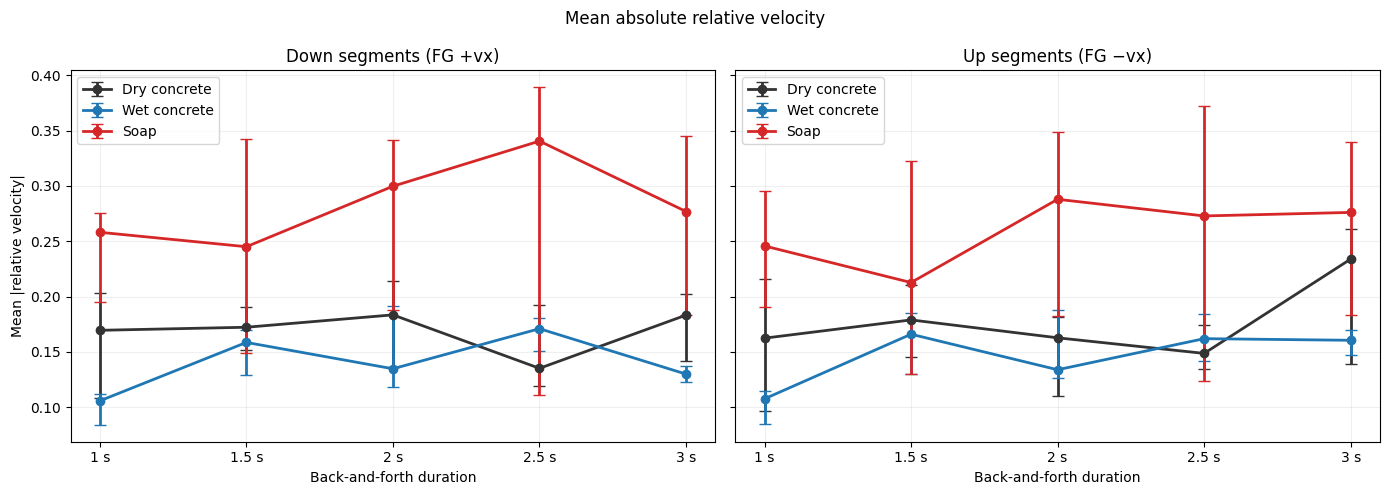

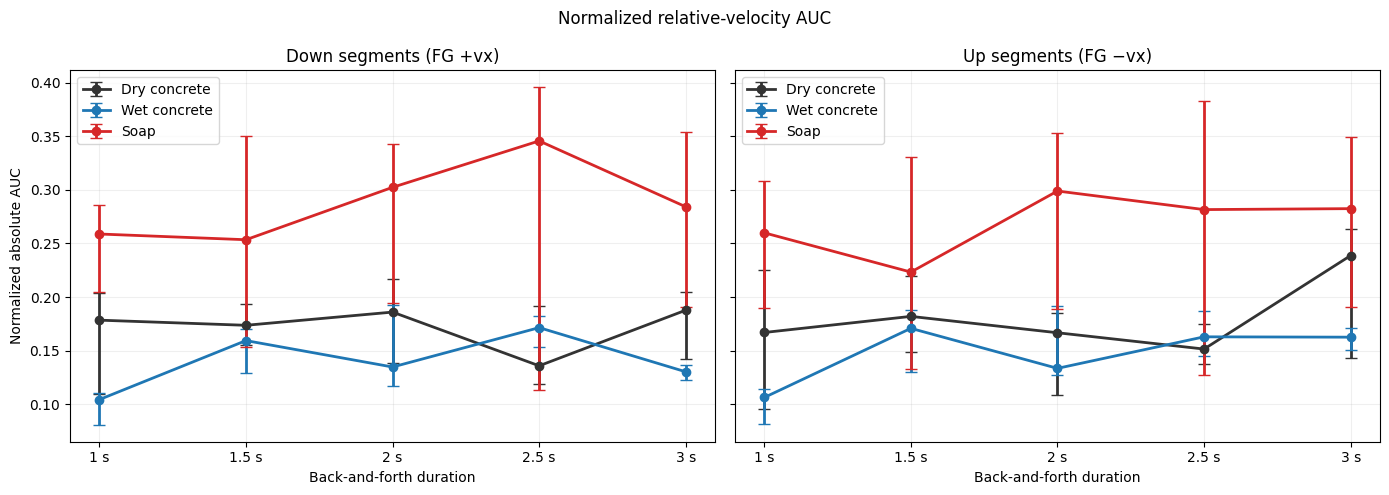

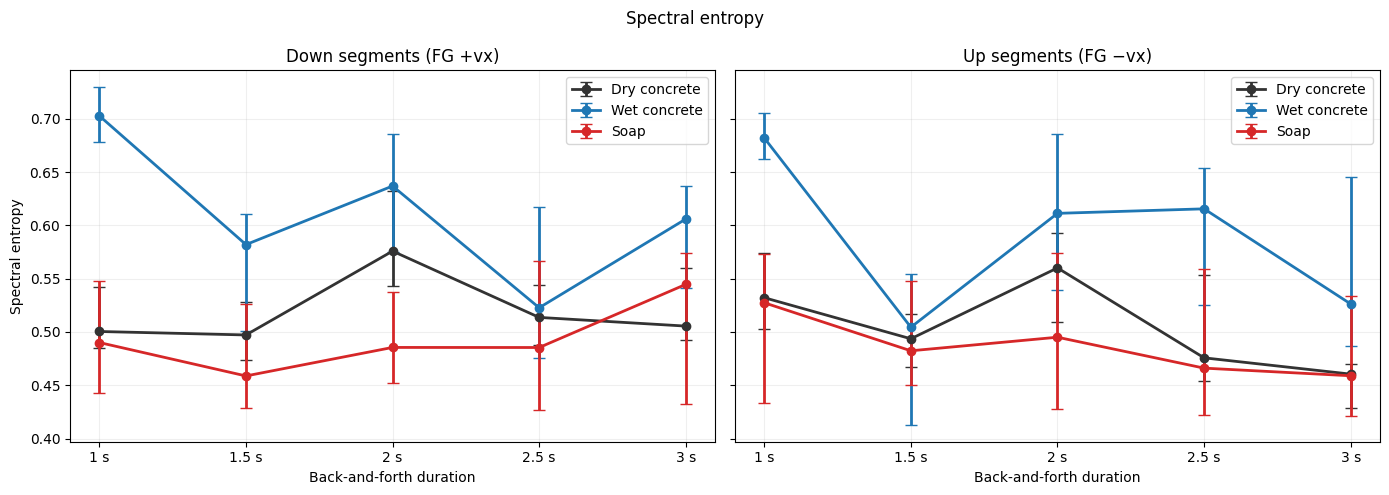

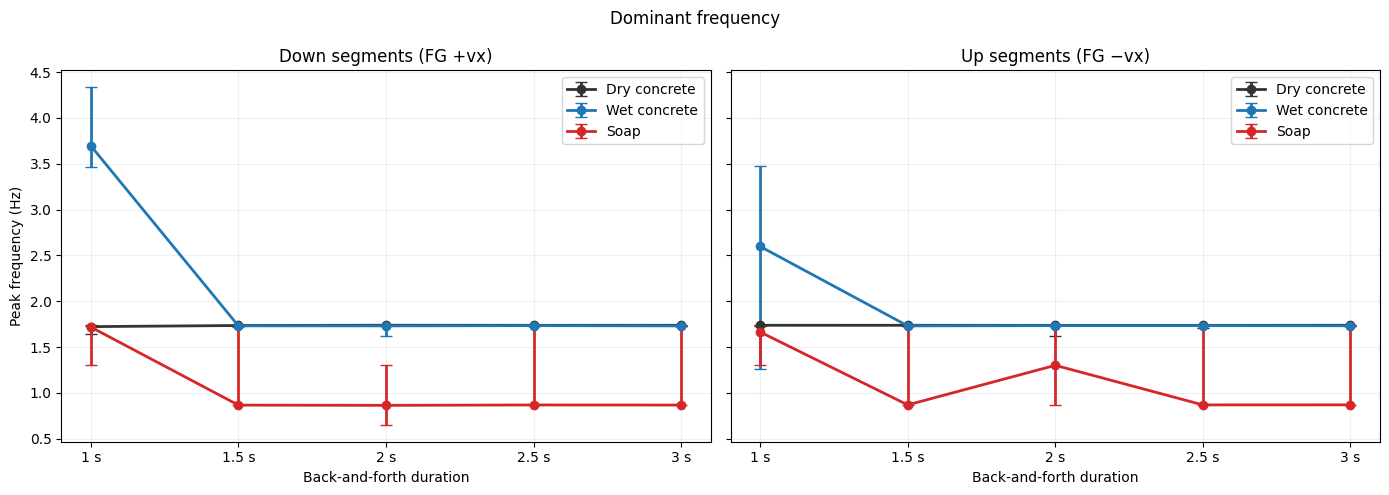

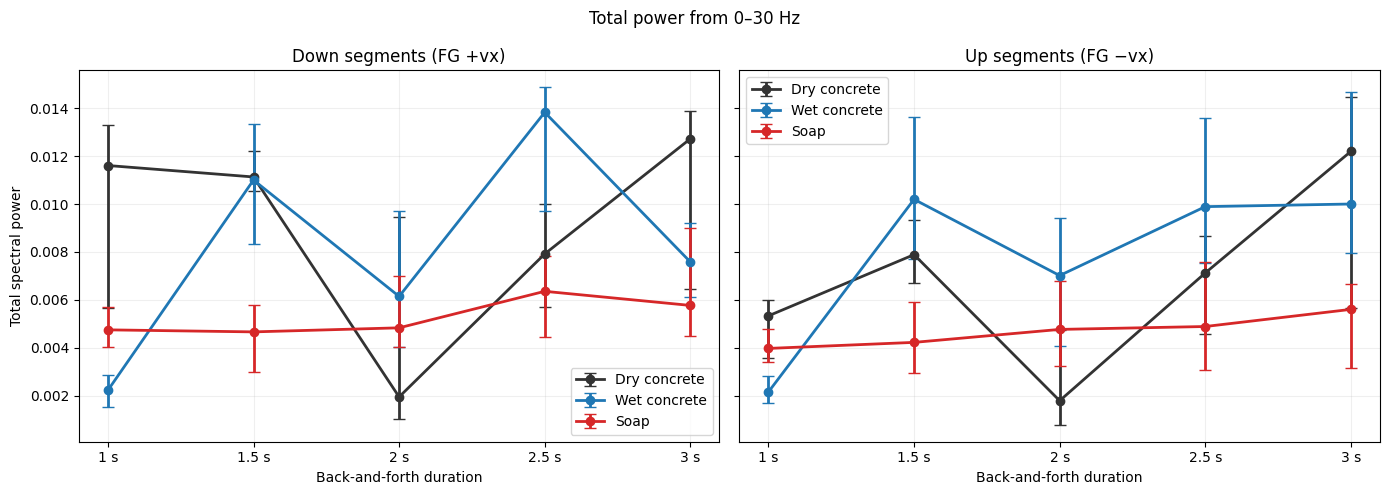

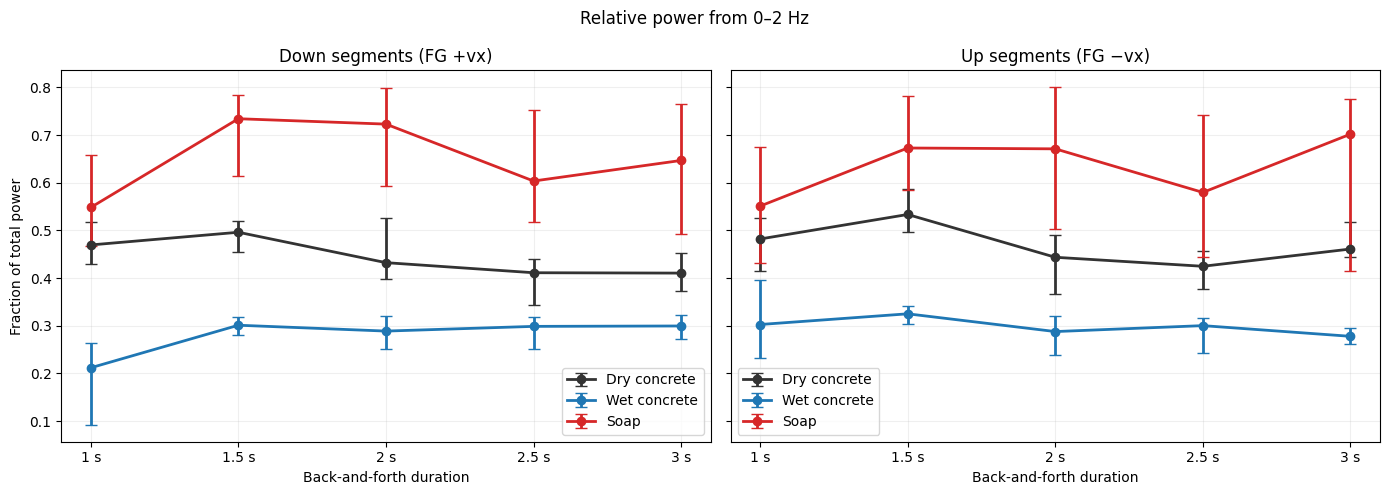

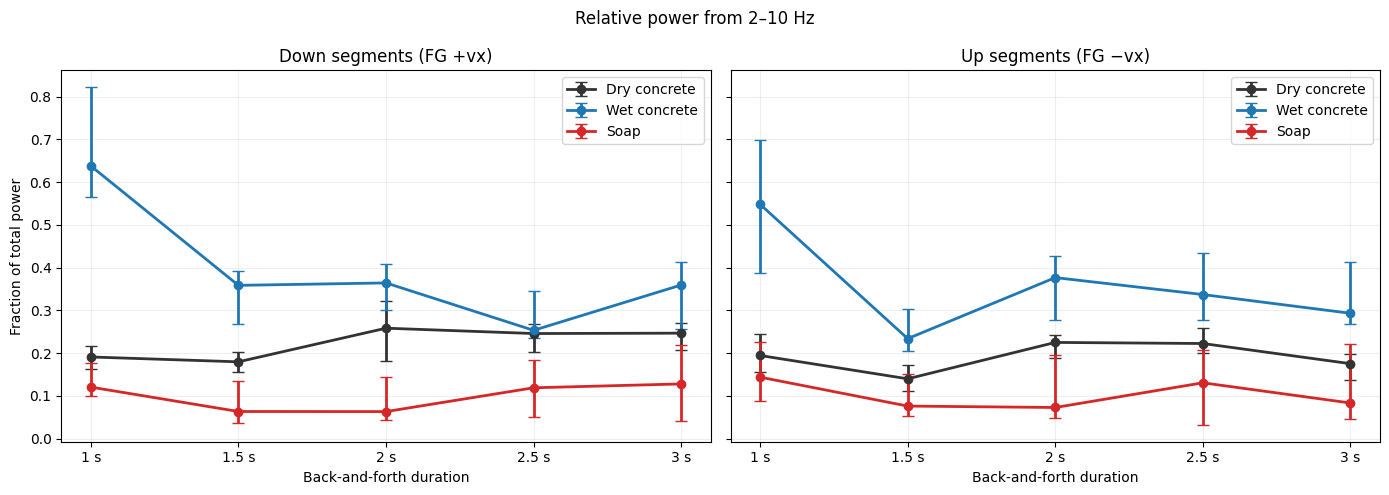

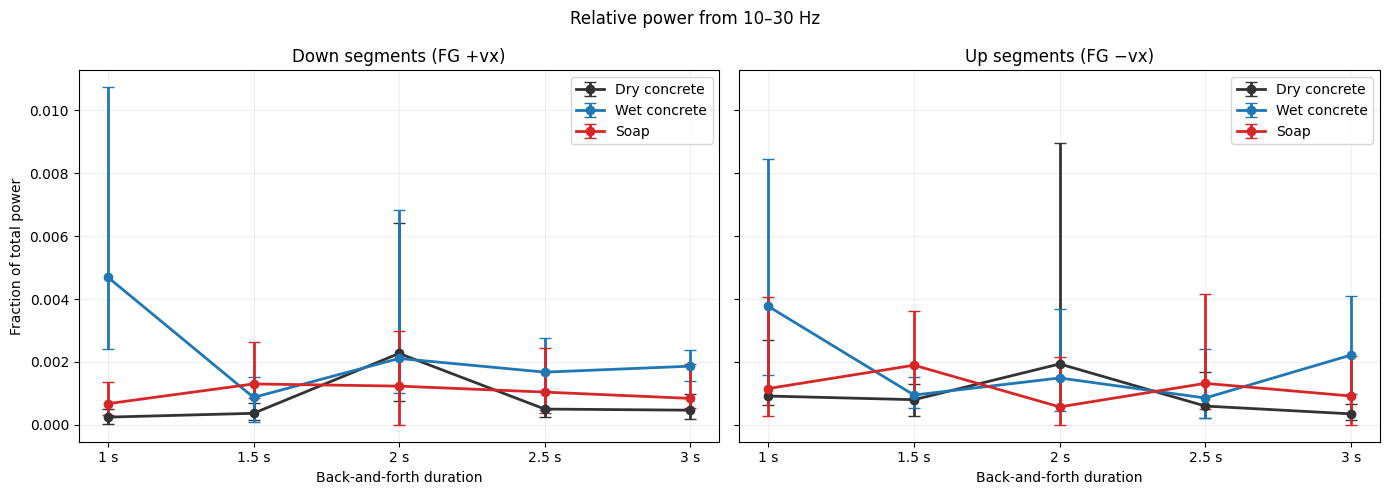

In [3]:
metric_plots = [
    (
        "mae",
        "Mean |relative velocity|",
        "Mean absolute relative velocity",
    ),
    (
        "auc_abs",
        "Normalized absolute AUC",
        "Normalized relative-velocity AUC",
    ),
    (
        "entropy",
        "Spectral entropy",
        "Spectral entropy",
    ),
    (
        "fpeak",
        "Peak frequency (Hz)",
        "Dominant frequency",
    ),
    (
        "p_total",
        "Total spectral power",
        "Total power from 0–30 Hz",
    ),
    (
        "r_0_2",
        "Fraction of total power",
        "Relative power from 0–2 Hz",
    ),
    (
        "r_2_10",
        "Fraction of total power",
        "Relative power from 2–10 Hz",
    ),
    (
        "r_10_30",
        "Fraction of total power",
        "Relative power from 10–30 Hz",
    ),
]


for metric, ylabel, title in metric_plots:
    plot_metric_comparison(
        metric,
        ylabel,
        title,
    )

In [4]:
# Determine a representative number of interpolation points
all_lengths = []

for surface, duration_map in category_keys.items():
    for duration, category in duration_map.items():
        for direction in ["down", "up"]:
            for segment in data[category][
                f"{direction}_vrel_segments"
            ]:
                all_lengths.append(len(segment))

n_points = int(np.median(all_lengths))
common_time = np.linspace(0, 1, n_points)


def calculate_median_curve(category, direction):

    velocity_segments = data[category][
        f"{direction}_vrel_segments"
    ]

    time_segments = data[category][
        f"{direction}_time_segments"
    ]

    curves = []

    for velocity_segment, time_segment in zip(
        velocity_segments,
        time_segments,
    ):
        velocity_segment = np.asarray(
            velocity_segment,
            dtype=float,
        )

        time_segment = np.asarray(
            time_segment,
            dtype=float,
        )

        n = min(
            len(velocity_segment),
            len(time_segment),
        )

        if n < 2:
            continue

        velocity_segment = velocity_segment[:n]
        time_segment = time_segment[:n]

        time_segment = (
            time_segment - time_segment[0]
        )

        duration = time_segment[-1]

        if duration <= 0:
            continue

        normalized_time = time_segment / duration

        curve = np.interp(
            common_time,
            normalized_time,
            velocity_segment,
        )

        curves.append(curve)

    curves = np.asarray(curves)

    if len(curves) == 0:
        return None, 0

    return np.median(curves, axis=0), len(curves)

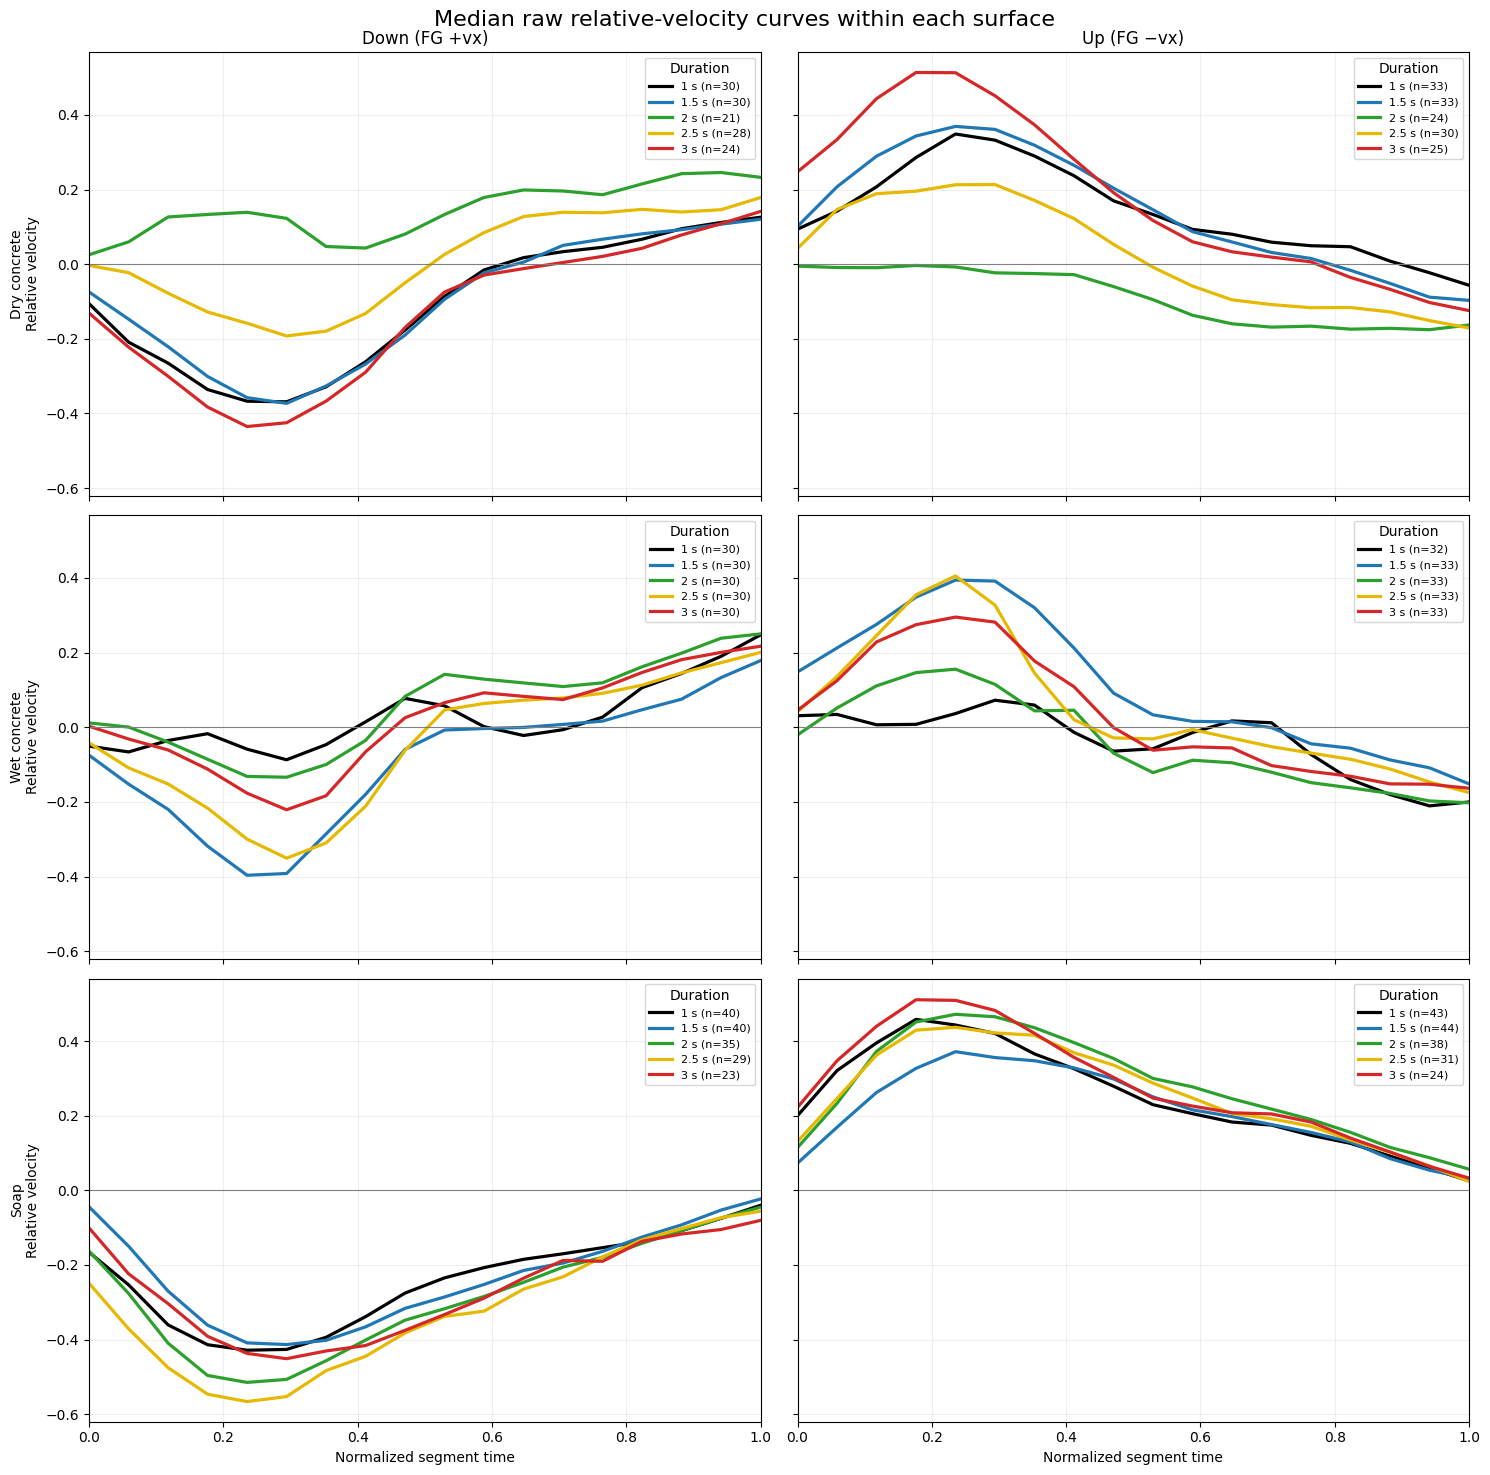

In [5]:
fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 15),
    sharex=True,
    sharey=True,
)

for row, (surface, duration_map) in enumerate(
    category_keys.items()
):
    for column, direction in enumerate(["down", "up"]):

        ax = axes[row, column]

        for duration in durations:

            category = duration_map[duration]

            median_curve, count = calculate_median_curve(
                category,
                direction,
            )

            if median_curve is None:
                continue

            ax.plot(
                common_time,
                median_curve,
                color=duration_colors[duration],
                linewidth=2.3,
                label=(
                    f"{duration_labels[duration]} "
                    f"(n={count})"
                ),
            )

        ax.axhline(
            0,
            color="gray",
            linewidth=0.8,
        )

        ax.set_xlim(0, 1)
        ax.grid(alpha=0.2)

        if row == 0:
            ax.set_title(
                "Down (FG +vx)"
                if direction == "down"
                else "Up (FG −vx)"
            )

        if column == 0:
            ax.set_ylabel(
                f"{surface}\nRelative velocity"
            )

        if row == 2:
            ax.set_xlabel("Normalized segment time")

        ax.legend(title="Duration", fontsize=8)

fig.suptitle(
    "Median raw relative-velocity curves within each surface",
    fontsize=16,
)

fig.tight_layout()
plt.show()

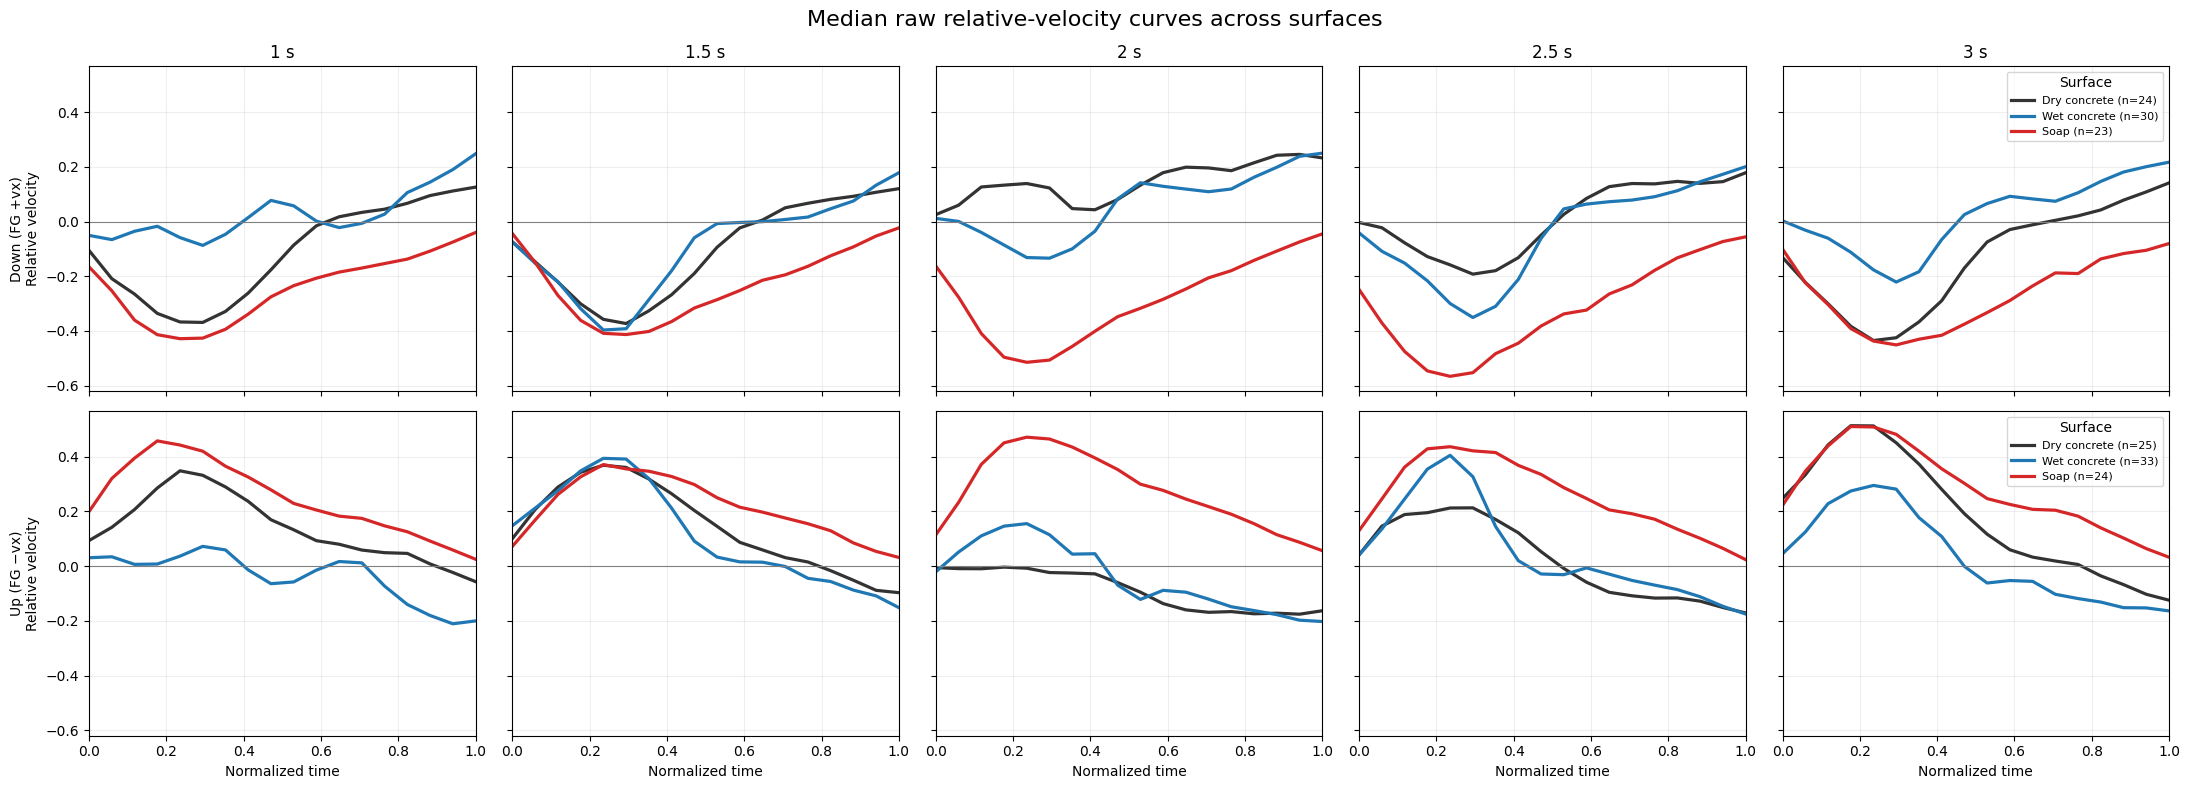

In [6]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(22, 8),
    sharex=True,
    sharey=True,
)

for column, duration in enumerate(durations):

    for row, direction in enumerate(["down", "up"]):

        ax = axes[row, column]

        for surface, duration_map in category_keys.items():

            category = duration_map[duration]

            median_curve, count = calculate_median_curve(
                category,
                direction,
            )

            if median_curve is None:
                continue

            ax.plot(
                common_time,
                median_curve,
                color=surface_colors[surface],
                linewidth=2.3,
                label=f"{surface} (n={count})",
            )

        ax.axhline(
            0,
            color="gray",
            linewidth=0.8,
        )

        ax.set_xlim(0, 1)
        ax.grid(alpha=0.2)

        if row == 0:
            ax.set_title(duration_labels[duration])

        if column == 0:
            ax.set_ylabel(
                "Down (FG +vx)\nRelative velocity"
                if direction == "down"
                else "Up (FG −vx)\nRelative velocity"
            )

        if row == 1:
            ax.set_xlabel("Normalized time")

        if column == 4:
            ax.legend(
                title="Surface",
                fontsize=8,
                loc="best",
            )

fig.suptitle(
    "Median raw relative-velocity curves across surfaces",
    fontsize=16,
)

fig.tight_layout()
plt.show()

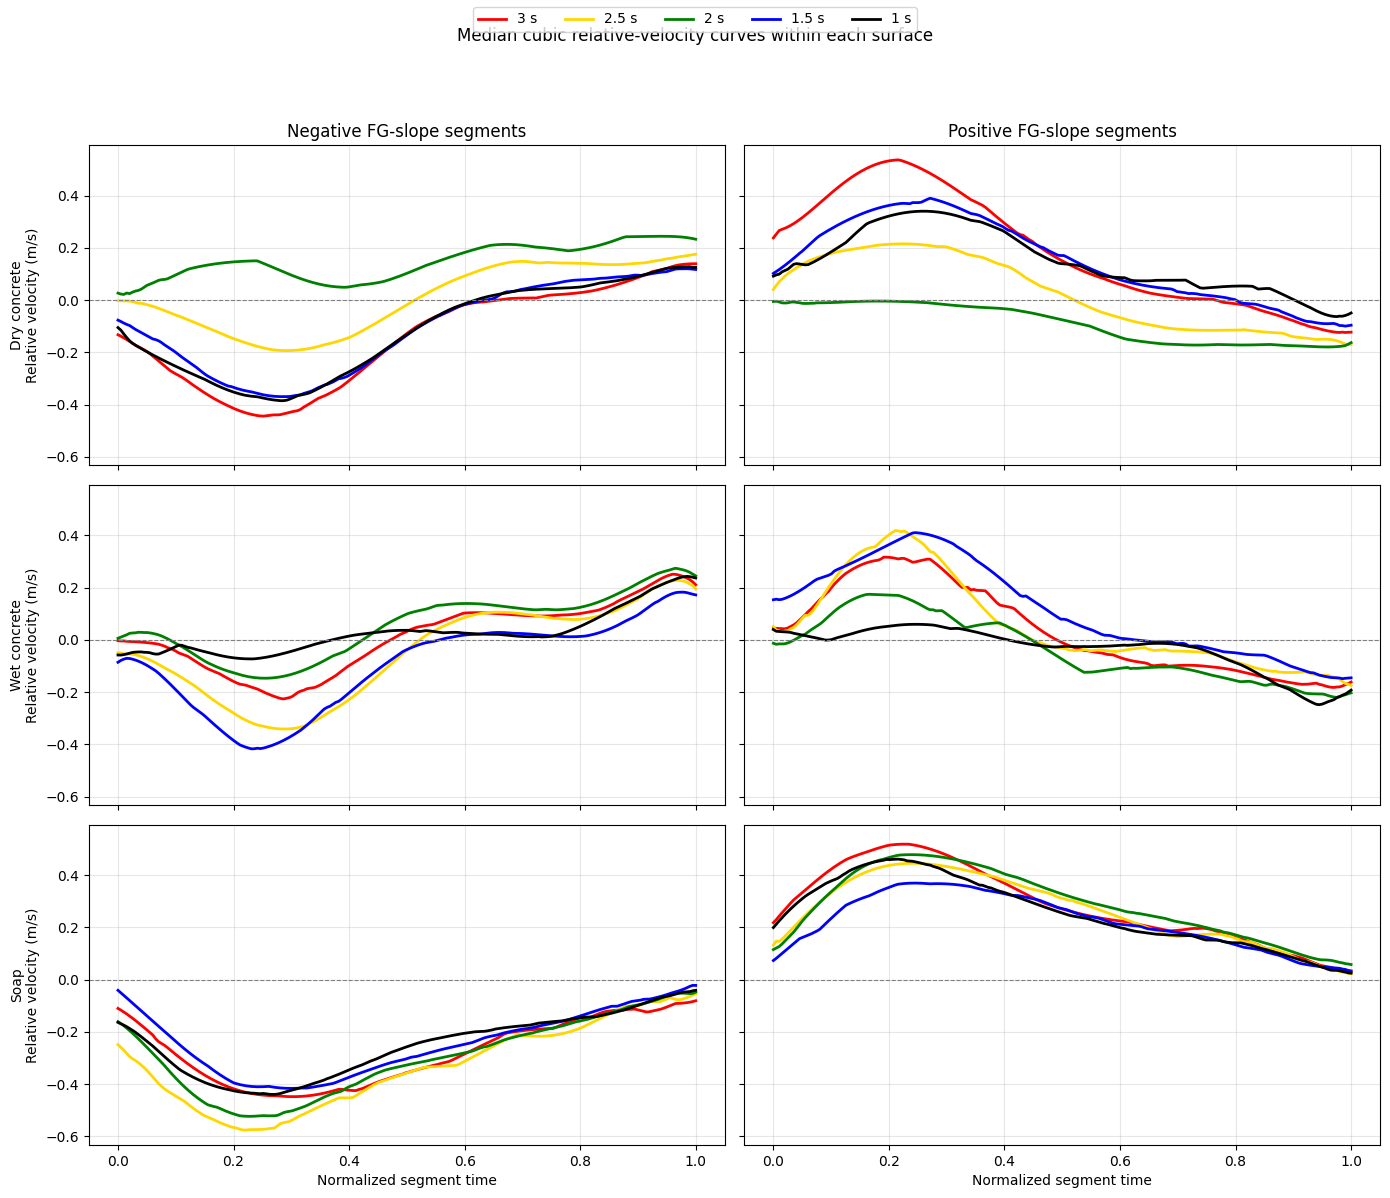

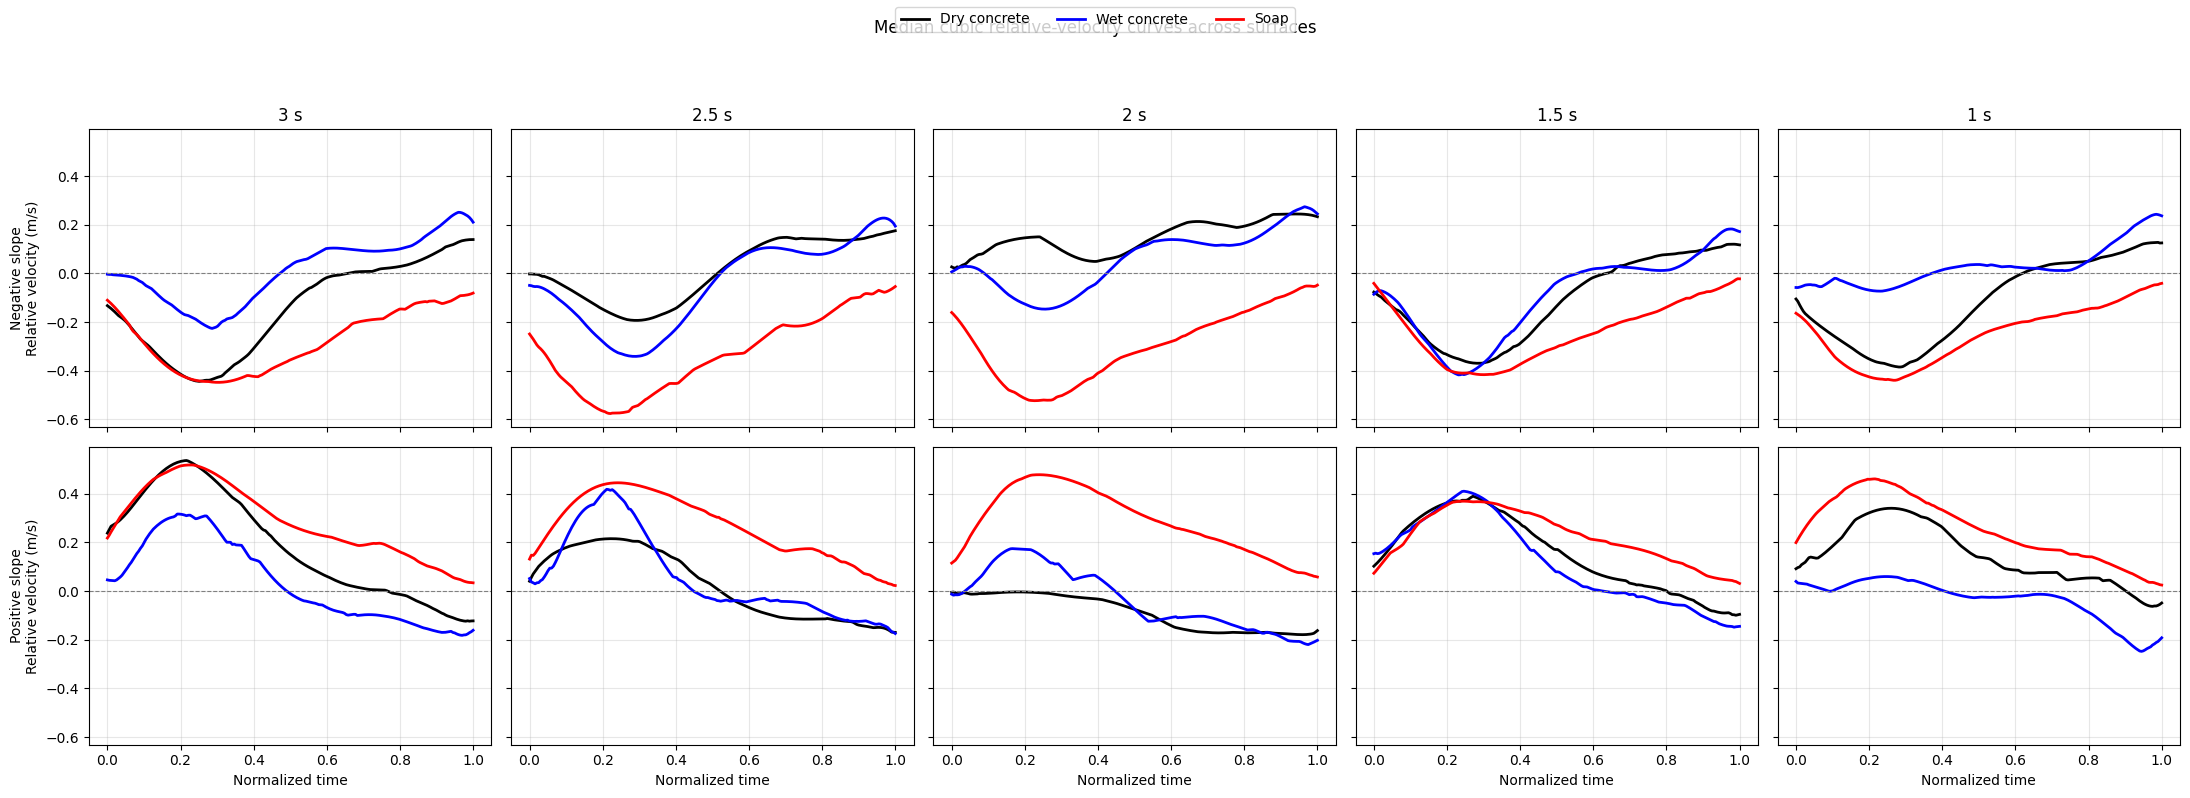

In [8]:
# Median polynomial-curve comparison

tau = np.linspace(0, 1, 200)

durations = [3.0, 2.5, 2.0, 1.5, 1.0]

duration_colors = {
    3.0: "red",
    2.5: "gold",
    2.0: "green",
    1.5: "blue",
    1.0: "black",
}

surface_colors = {
    "Dry concrete": "black",
    "Wet concrete": "blue",
    "Soap": "red",
}


def median_polynomial_curve(category_key, direction):
    coefficients = np.asarray(
        data[category_key][f"{direction}_poly7_coeffs"],
        dtype=float
    )

    curves = np.asarray([
        np.polyval(coeff, tau)
        for coeff in coefficients
    ])

    return np.median(curves, axis=0)


# ==================================================
# 1) Compare five durations within each surface
# ==================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(14, 12),
    sharex=True,
    sharey=True
)

for row, (surface, category_map) in enumerate(category_keys.items()):

    for duration in durations:

        category_key = category_map[duration]

        down_median = median_polynomial_curve(
            category_key,
            "down"
        )

        up_median = median_polynomial_curve(
            category_key,
            "up"
        )

        axes[row, 0].plot(
            tau,
            down_median,
            color=duration_colors[duration],
            linewidth=2,
            label=f"{duration:g} s"
        )

        axes[row, 1].plot(
            tau,
            up_median,
            color=duration_colors[duration],
            linewidth=2,
            label=f"{duration:g} s"
        )

    axes[row, 0].set_ylabel(
        f"{surface}\nRelative velocity (m/s)"
    )

    for col in range(2):
        axes[row, col].axhline(
            0,
            color="gray",
            linestyle="--",
            linewidth=0.8
        )
        axes[row, col].grid(True, alpha=0.3)

axes[0, 0].set_title("Negative FG-slope segments")
axes[0, 1].set_title("Positive FG-slope segments")

axes[-1, 0].set_xlabel("Normalized segment time")
axes[-1, 1].set_xlabel("Normalized segment time")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5
)

fig.suptitle(
    "Median cubic relative-velocity curves within each surface",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


# ==================================================
# 2) Compare three surfaces at each fixed duration
# ==================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(22, 8),
    sharex=True,
    sharey=True
)

for col, duration in enumerate(durations):

    for surface, category_map in category_keys.items():

        category_key = category_map[duration]

        axes[0, col].plot(
            tau,
            median_polynomial_curve(category_key, "down"),
            color=surface_colors[surface],
            linewidth=2,
            label=surface
        )

        axes[1, col].plot(
            tau,
            median_polynomial_curve(category_key, "up"),
            color=surface_colors[surface],
            linewidth=2,
            label=surface
        )

    axes[0, col].set_title(f"{duration:g} s")

    axes[1, col].set_xlabel("Normalized time")

    for row in range(2):
        axes[row, col].axhline(
            0,
            color="gray",
            linestyle="--",
            linewidth=0.8
        )
        axes[row, col].grid(True, alpha=0.3)

axes[0, 0].set_ylabel(
    "Negative slope\nRelative velocity (m/s)"
)

axes[1, 0].set_ylabel(
    "Positive slope\nRelative velocity (m/s)"
)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3
)

fig.suptitle(
    "Median cubic relative-velocity curves across surfaces",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

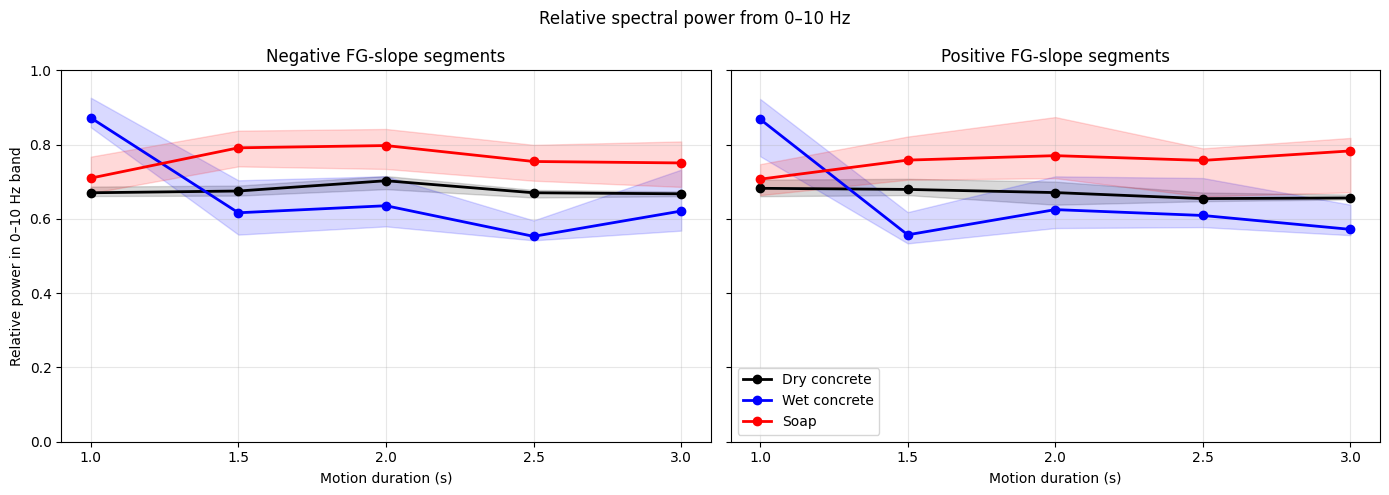

In [9]:
# Add derived 0–10 Hz relative-power values

for category_data in data.values():

    for direction in ["down", "up"]:

        r_0_2 = np.asarray(
            category_data[f"{direction}_r_0_2"],
            dtype=float
        )

        r_2_10 = np.asarray(
            category_data[f"{direction}_r_2_10"],
            dtype=float
        )

        category_data[f"{direction}_r_0_10"] = (
            r_0_2 + r_2_10
        ).tolist()


# Plot comparison

durations_plot = [1.0, 1.5, 2.0, 2.5, 3.0]

surface_colors = {
    "Dry concrete": "black",
    "Wet concrete": "blue",
    "Soap": "red",
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

for surface, category_map in category_keys.items():

    for ax, direction in zip(
        axes,
        ["down", "up"]
    ):

        medians = []
        q25_values = []
        q75_values = []

        for duration in durations_plot:

            category_key = category_map[duration]

            values = np.asarray(
                data[category_key][
                    f"{direction}_r_0_10"
                ],
                dtype=float
            )

            medians.append(np.nanmedian(values))
            q25_values.append(
                np.nanpercentile(values, 25)
            )
            q75_values.append(
                np.nanpercentile(values, 75)
            )

        color = surface_colors[surface]

        ax.plot(
            durations_plot,
            medians,
            color=color,
            marker="o",
            linewidth=2,
            label=surface
        )

        ax.fill_between(
            durations_plot,
            q25_values,
            q75_values,
            color=color,
            alpha=0.15
        )

axes[0].set_title("Negative FG-slope segments")
axes[1].set_title("Positive FG-slope segments")

for ax in axes:
    ax.set_xlabel("Motion duration (s)")
    ax.set_xticks(durations_plot)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Relative power in 0–10 Hz band")
axes[1].legend()

plt.suptitle("Relative spectral power from 0–10 Hz")
plt.tight_layout()
plt.show()

,Condition,Slope,Segments,Median duration (s),Median true resolution (Hz)
0,Concrete,Negative,32,0.399,2.505
1,Concrete,Positive,32,0.400,2.501
2,Vinyl,Negative,36,0.387,2.582
3,Vinyl,Positive,39,0.360,2.775
4,Board,Negative,45,0.498,2.006
5,Board,Positive,47,0.480,2.083
6,Soap,Negative,56,0.801,1.248
7,Soap,Positive,61,0.801,1.249
8,Carpet,Negative,37,0.544,1.837
9,Carpet,Positive,37,0.541,1.850


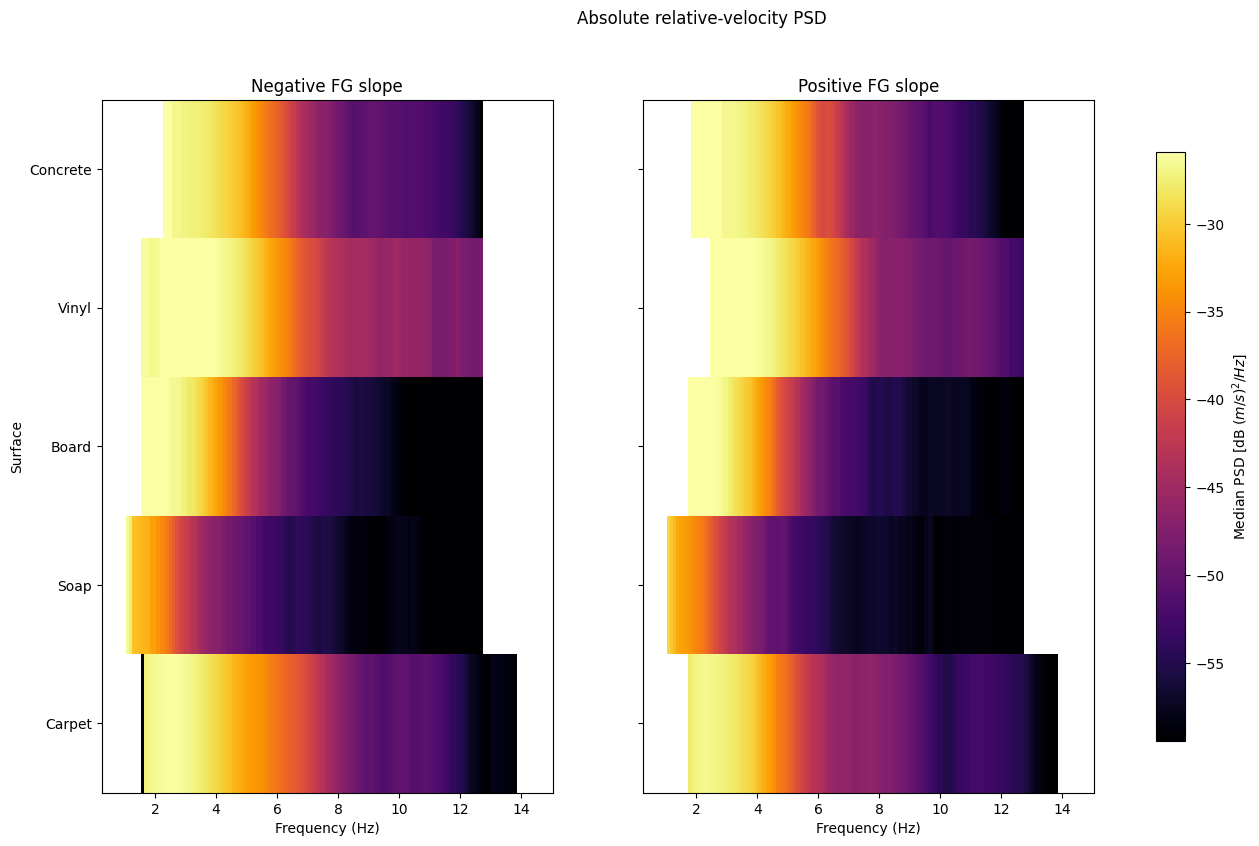

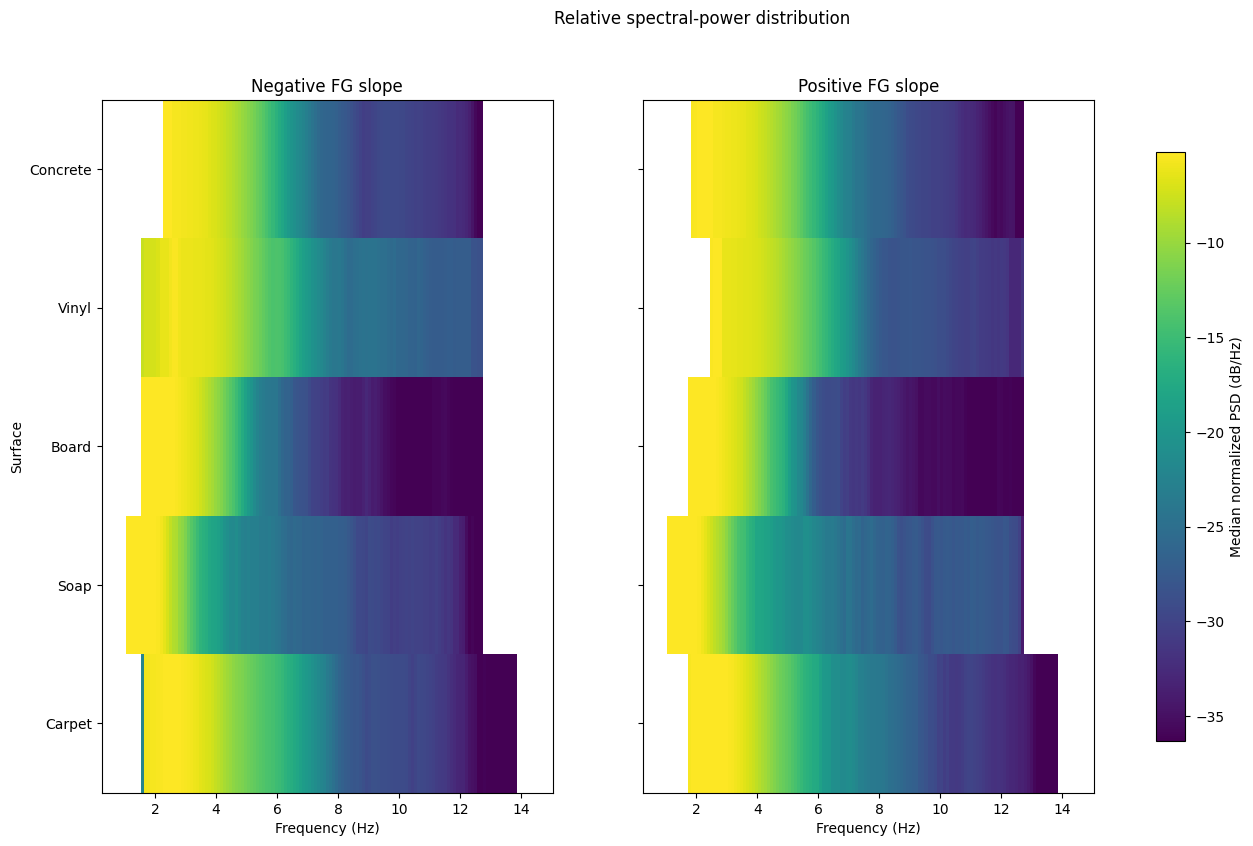

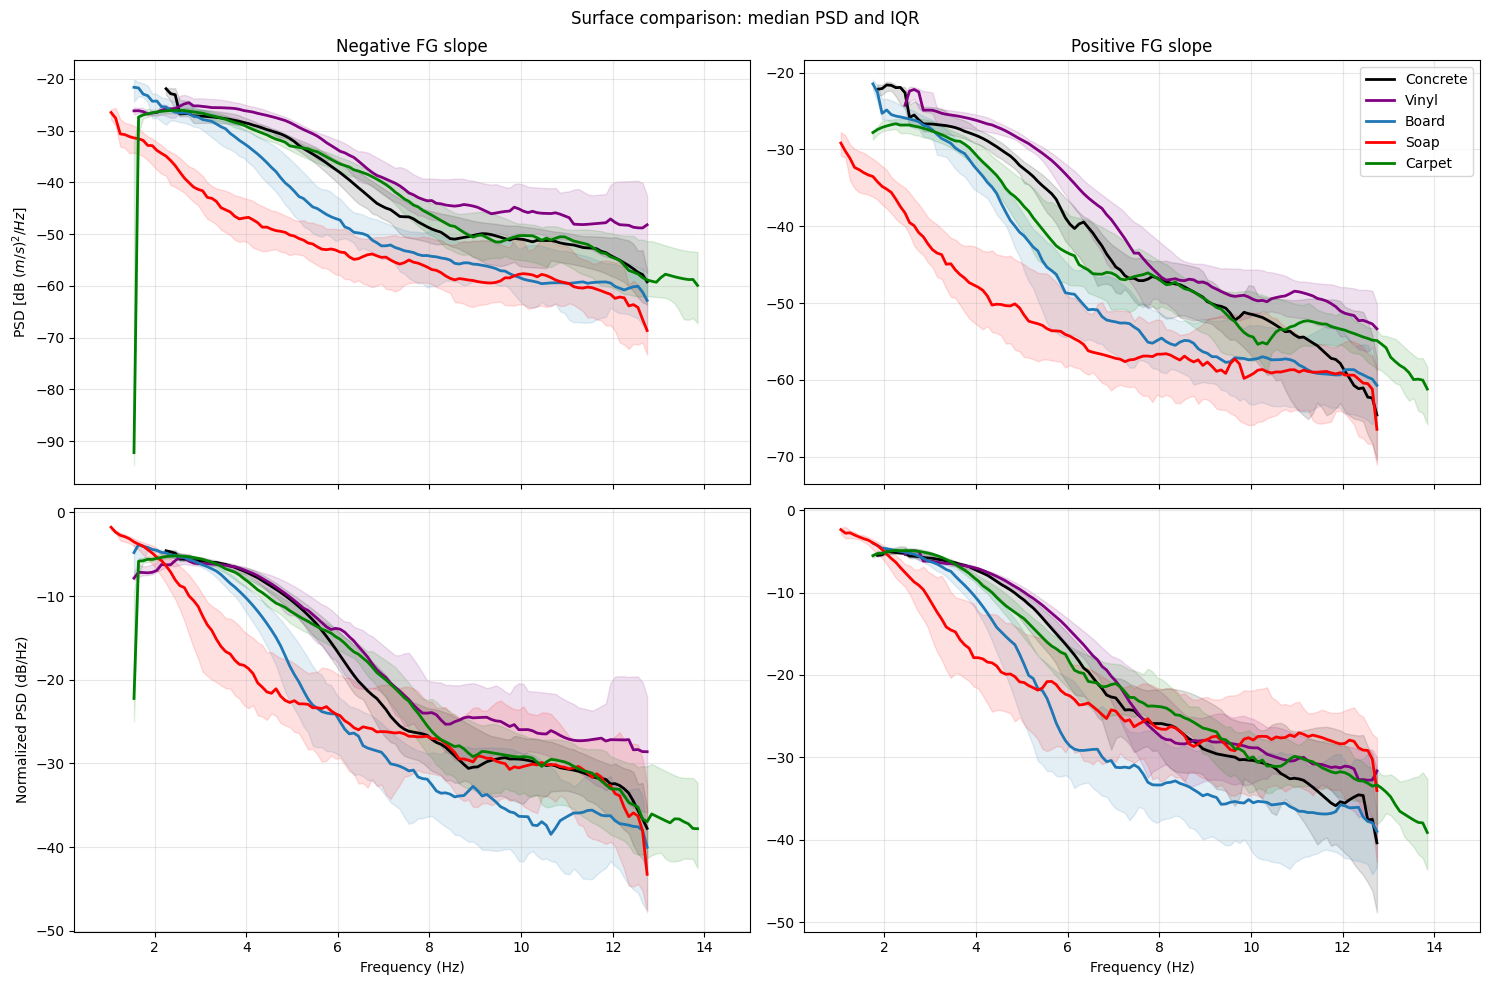

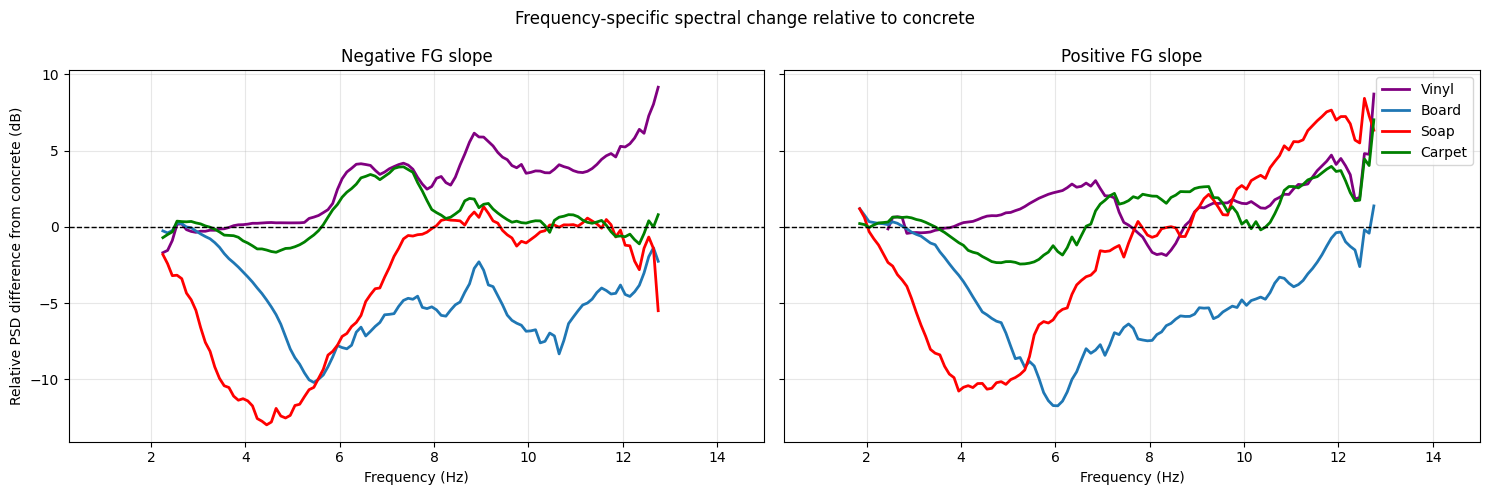

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch


NPZ_FILE = "Surface_spectral_analysis.npz"

npz = np.load(
    NPZ_FILE,
    allow_pickle=True
)

data = npz["data"].item()


# ============================================================
# Settings
# ============================================================

FREQ_MIN = 0.25
FREQ_MAX = 15.0
FREQ_STEP = 0.10

frequency_grid = np.arange(
    FREQ_MIN,
    FREQ_MAX + FREQ_STEP,
    FREQ_STEP
)

condition_order = [
    "Concrete",
    "Vinyl",
    "Board",
    "Soap",
    "Carpet",
]

condition_order = [
    key for key in condition_order
    if key in data
]

condition_labels = {
    "Concrete": "Concrete",
    "Vinyl": "Vinyl",
    "Board": "Board",
    "Soap": "Soap",
    "Carpet": "Carpet",
}


# ============================================================
# Calculate PSD matrix for one condition and direction
# ============================================================

def calculate_psd_matrix(category_key, direction):

    velocity_segments = data[category_key][
        f"{direction}_vrel_segments"
    ]

    time_segments = data[category_key][
        f"{direction}_time_segments"
    ]

    absolute_psds = []
    relative_psds = []
    segment_durations = []
    frequency_resolutions = []

    for velocity, time in zip(
        velocity_segments,
        time_segments
    ):

        velocity = np.asarray(
            velocity,
            dtype=float
        ).ravel()

        time = np.asarray(
            time,
            dtype=float
        ).ravel()

        n = min(len(velocity), len(time))

        velocity = velocity[:n]
        time = time[:n]

        valid = (
            np.isfinite(velocity)
            & np.isfinite(time)
        )

        velocity = velocity[valid]
        time = time[valid]

        if len(time) < 8:
            continue

        duration = float(time[-1] - time[0])

        if duration <= 0:
            continue

        dt = float(np.median(np.diff(time)))

        if dt <= 0:
            continue

        # Resample onto a uniform time grid because Welch assumes
        # uniformly sampled data
        time_uniform = np.arange(
            time[0],
            time[-1] + 0.5 * dt,
            dt
        )

        velocity_uniform = np.interp(
            time_uniform,
            time,
            velocity
        )

        if len(velocity_uniform) < 8:
            continue

        sampling_frequency = 1.0 / dt

        nperseg = min(
            128,
            len(velocity_uniform)
        )

        noverlap = nperseg // 2

        nfft = max(
            256,
            2 ** int(np.ceil(np.log2(nperseg)))
        )

        frequency, psd = welch(
            velocity_uniform,
            fs=sampling_frequency,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nfft,
            detrend="linear",
            scaling="density"
        )

        psd_on_grid = np.interp(
            frequency_grid,
            frequency,
            psd,
            left=np.nan,
            right=np.nan
        )

        # Normalize by total power from 0.25–30 Hz
        analysis_band = (
            (frequency >= FREQ_MIN)
            & (frequency <= FREQ_MAX)
        )

        total_power = np.trapezoid(
            psd[analysis_band],
            frequency[analysis_band]
        )

        if total_power <= 0:
            continue

        relative_psd = (
            psd_on_grid / total_power
        )

        # A segment of duration T cannot reliably resolve
        # frequencies substantially below 1/T
        true_resolution = 1.0 / duration

        unresolved = (
            frequency_grid < true_resolution
        )

        psd_on_grid[unresolved] = np.nan
        relative_psd[unresolved] = np.nan

        absolute_psds.append(psd_on_grid)
        relative_psds.append(relative_psd)

        segment_durations.append(duration)
        frequency_resolutions.append(
            true_resolution
        )

    return {
        "absolute": np.asarray(
            absolute_psds,
            dtype=float
        ),
        "relative": np.asarray(
            relative_psds,
            dtype=float
        ),
        "durations": np.asarray(
            segment_durations,
            dtype=float
        ),
        "resolution": np.asarray(
            frequency_resolutions,
            dtype=float
        ),
    }


# ============================================================
# Calculate matrices for every condition
# ============================================================

psd_results = {}

for category_key in condition_order:

    psd_results[category_key] = {
        "down": calculate_psd_matrix(
            category_key,
            "down"
        ),
        "up": calculate_psd_matrix(
            category_key,
            "up"
        ),
    }


# ============================================================
# Frequency-wise median and IQR
# Require at least 3 valid segments at each frequency
# ============================================================

def summarize_psd(matrix, minimum_segments=3):

    median = np.full(
        len(frequency_grid),
        np.nan
    )

    q25 = np.full_like(median, np.nan)
    q75 = np.full_like(median, np.nan)
    counts = np.zeros_like(median, dtype=int)

    for j in range(len(frequency_grid)):

        values = matrix[:, j]

        values = values[
            np.isfinite(values)
        ]

        counts[j] = len(values)

        if len(values) >= minimum_segments:

            median[j] = np.median(values)
            q25[j] = np.percentile(values, 25)
            q75[j] = np.percentile(values, 75)

    return median, q25, q75, counts


def to_db(values):
    return 10 * np.log10(
        np.maximum(values, 1e-20)
    )


# ============================================================
# Show segment counts and actual frequency resolution
# ============================================================

summary_rows = []

for category_key in condition_order:

    for direction in ["down", "up"]:

        result = psd_results[
            category_key
        ][direction]

        summary_rows.append({
            "Condition": condition_labels[category_key],
            "Slope": (
                "Negative"
                if direction == "down"
                else "Positive"
            ),
            "Segments": len(result["durations"]),
            "Median duration (s)": np.median(
                result["durations"]
            ),
            "Median true resolution (Hz)": np.median(
                result["resolution"]
            ),
        })

display(
    pd.DataFrame(summary_rows).round(3)
)


# ============================================================
# Heatmap function
# ============================================================

def make_heatmap_data(direction, spectrum_type):

    rows = []

    for category_key in condition_order:

        matrix = psd_results[
            category_key
        ][direction][spectrum_type]

        median, _, _, _ = summarize_psd(matrix)

        rows.append(to_db(median))

    return np.asarray(rows)


# ============================================================
# 1) Absolute PSD heatmaps
# ============================================================

absolute_down = make_heatmap_data(
    "down",
    "absolute"
)

absolute_up = make_heatmap_data(
    "up",
    "absolute"
)

finite_absolute = np.concatenate([
    absolute_down[np.isfinite(absolute_down)],
    absolute_up[np.isfinite(absolute_up)]
])

abs_vmin, abs_vmax = np.percentile(
    finite_absolute,
    [5, 95]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 9),
    sharey=True
)

for ax, heatmap, title in zip(
    axes,
    [absolute_down, absolute_up],
    ["Negative FG slope", "Positive FG slope"]
):

    image = ax.imshow(
        heatmap,
        aspect="auto",
        origin="upper",
        extent=[
            frequency_grid[0],
            frequency_grid[-1],
            len(condition_order) - 0.5,
            -0.5
        ],
        cmap="inferno",
        vmin=abs_vmin,
        vmax=abs_vmax
    )

    ax.set_title(title)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_yticks(
        np.arange(len(condition_order))
    )
    ax.set_yticklabels([
        condition_labels[key]
        for key in condition_order
    ])

axes[0].set_ylabel("Surface")

colorbar = fig.colorbar(
    image,
    ax=axes,
    shrink=0.85
)

colorbar.set_label(
    r"Median PSD [dB $(m/s)^2/Hz$]"
)

fig.suptitle(
    "Absolute relative-velocity PSD"
)

plt.show()


# ============================================================
# 2) Relative PSD heatmaps
# ============================================================

relative_down = make_heatmap_data(
    "down",
    "relative"
)

relative_up = make_heatmap_data(
    "up",
    "relative"
)

finite_relative = np.concatenate([
    relative_down[np.isfinite(relative_down)],
    relative_up[np.isfinite(relative_up)]
])

rel_vmin, rel_vmax = np.percentile(
    finite_relative,
    [5, 95]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 9),
    sharey=True
)

for ax, heatmap, title in zip(
    axes,
    [relative_down, relative_up],
    ["Negative FG slope", "Positive FG slope"]
):

    image = ax.imshow(
        heatmap,
        aspect="auto",
        origin="upper",
        extent=[
            frequency_grid[0],
            frequency_grid[-1],
            len(condition_order) - 0.5,
            -0.5
        ],
        cmap="viridis",
        vmin=rel_vmin,
        vmax=rel_vmax
    )

    ax.set_title(title)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_yticks(
        np.arange(len(condition_order))
    )
    ax.set_yticklabels([
        condition_labels[key]
        for key in condition_order
    ])

axes[0].set_ylabel("Surface")

colorbar = fig.colorbar(
    image,
    ax=axes,
    shrink=0.85
)

colorbar.set_label(
    "Median normalized PSD (dB/Hz)"
)

fig.suptitle(
    "Relative spectral-power distribution"
)

plt.show()


# ============================================================
# 3) Detailed comparison of all surfaces
# ============================================================

surfaces = {
    "Concrete": "Concrete",
    "Vinyl": "Vinyl",
    "Board": "Board",
    "Soap": "Soap",
    "Carpet": "Carpet",
}

surfaces = {
    surface: key
    for surface, key in surfaces.items()
    if key in psd_results
}

surface_colors = {
    "Concrete": "black",
    "Vinyl": "purple",
    "Board": "tab:blue",
    "Soap": "red",
    "Carpet": "green",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
    sharex=True
)

for col, direction in enumerate(
    ["down", "up"]
):

    for surface, category_key in surfaces.items():

        color = surface_colors[surface]

        # Absolute PSD
        matrix = psd_results[
            category_key
        ][direction]["absolute"]

        median, q25, q75, _ = summarize_psd(
            matrix
        )

        axes[0, col].plot(
            frequency_grid,
            to_db(median),
            color=color,
            linewidth=2,
            label=surface
        )

        axes[0, col].fill_between(
            frequency_grid,
            to_db(q25),
            to_db(q75),
            color=color,
            alpha=0.12
        )

        # Relative PSD
        matrix = psd_results[
            category_key
        ][direction]["relative"]

        median, q25, q75, _ = summarize_psd(
            matrix
        )

        axes[1, col].plot(
            frequency_grid,
            to_db(median),
            color=color,
            linewidth=2,
            label=surface
        )

        axes[1, col].fill_between(
            frequency_grid,
            to_db(q25),
            to_db(q75),
            color=color,
            alpha=0.12
        )

    slope_name = (
        "Negative FG slope"
        if direction == "down"
        else "Positive FG slope"
    )

    axes[0, col].set_title(slope_name)
    axes[1, col].set_xlabel("Frequency (Hz)")

for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
    ax.set_xlim(FREQ_MIN, FREQ_MAX)

axes[0, 0].set_ylabel(
    r"PSD [dB $(m/s)^2/Hz$]"
)

axes[1, 0].set_ylabel(
    "Normalized PSD (dB/Hz)"
)

axes[0, 1].legend()

fig.suptitle(
    "Surface comparison: median PSD and IQR"
)

plt.tight_layout()
plt.show()


# ============================================================
# 4) Relative PSD differences against concrete
# ============================================================

reference_key = "Concrete"

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5),
    sharey=True
)

if reference_key in psd_results:

    for ax, direction in zip(
        axes,
        ["down", "up"]
    ):

        reference_matrix = psd_results[
            reference_key
        ][direction]["relative"]

        reference_median, _, _, _ = summarize_psd(
            reference_matrix
        )

        for surface, category_key in surfaces.items():

            if category_key == reference_key:
                continue

            surface_matrix = psd_results[
                category_key
            ][direction]["relative"]

            surface_median, _, _, _ = summarize_psd(
                surface_matrix
            )

            difference_db = (
                to_db(surface_median)
                - to_db(reference_median)
            )

            ax.plot(
                frequency_grid,
                difference_db,
                color=surface_colors[surface],
                linewidth=2,
                label=surface
            )

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1
        )

        ax.set_title(
            "Negative FG slope"
            if direction == "down"
            else "Positive FG slope"
        )

        ax.set_xlabel("Frequency (Hz)")
        ax.set_xlim(FREQ_MIN, FREQ_MAX)
        ax.grid(True, alpha=0.3)

axes[0].set_ylabel(
    "Relative PSD difference from concrete (dB)"
)

axes[1].legend()

fig.suptitle(
    "Frequency-specific spectral change relative to concrete"
)

plt.tight_layout()
plt.show()


# Optional: save the numerical PSD matrices separately
# np.savez(
#     "PSD_matrices.npz",
#     psd_results=psd_results,
#     frequency_grid=frequency_grid
# )


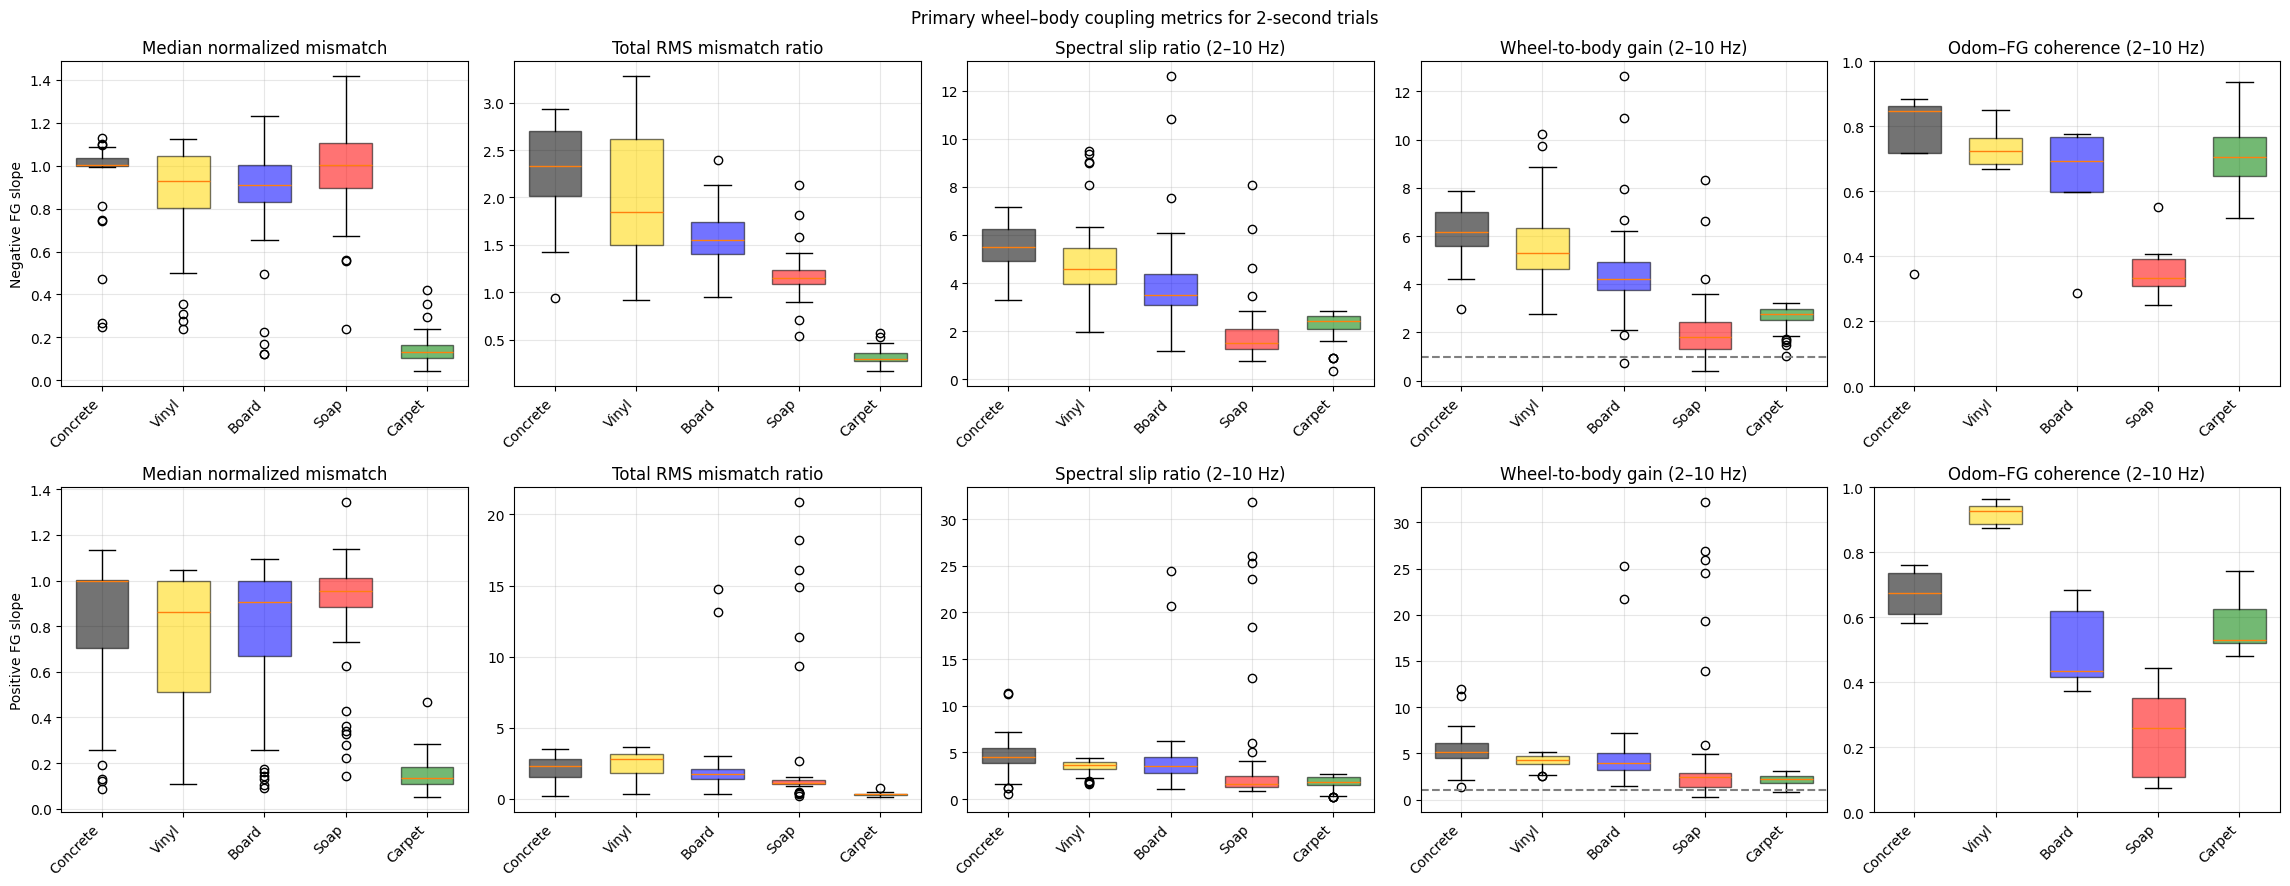

In [12]:
import numpy as np
import matplotlib.pyplot as plt


NPZ_FILE = "Surface_spectral_analysis.npz"

data = np.load(
    NPZ_FILE,
    allow_pickle=True
)["data"].item()


NPZ_FILE = "Surface_spectral_analysis.npz"

surface_2s = {
    "Concrete": "Concrete",
    "Vinyl": "Vinyl",
    "Board": "Board",
    "Soap": "Soap",
    "Carpet": "Carpet",
}

surface_colors = {
    "Concrete": "black",
    "Vinyl": "gold",
    "Board": "blue",
    "Soap": "red",
    "Carpet": "green",
}

directions = {
    "down": "Negative FG slope",
    "up": "Positive FG slope",
}


primary_metrics = {
    "median_abs_slip_ratio":
        "Median normalized mismatch",

    "rms_mismatch_ratio":
        "Total RMS mismatch ratio",

    "spectral_slip_ratio_2_10":
        "Spectral slip ratio (2–10 Hz)",

    "band_transfer_gain_2_10":
        "Wheel-to-body gain (2–10 Hz)",

    "coherence_2_10":
        "Odom–FG coherence (2–10 Hz)",
}


fig, axes = plt.subplots(
    2,
    5,
    figsize=(23, 9)
)

for row, (
    direction,
    direction_title
) in enumerate(directions.items()):

    for col, (
        metric,
        metric_label
    ) in enumerate(
        primary_metrics.items()
    ):

        ax = axes[row, col]

        values_by_surface = []

        for surface, category_key in (
            surface_2s.items()
        ):

            values = np.asarray(
                data[category_key][
                    f"{direction}_{metric}"
                ],
                dtype=float
            )

            values = values[
                np.isfinite(values)
            ]

            values_by_surface.append(values)

        boxplot = ax.boxplot(
            values_by_surface,
            patch_artist=True,
            showfliers=True,
            widths=0.65
        )

        for patch, surface in zip(
            boxplot["boxes"],
            surface_2s.keys()
        ):
            patch.set_facecolor(
                surface_colors[surface]
            )
            patch.set_alpha(0.55)

        ax.set_xticks(
            np.arange(
                1,
                len(surface_2s) + 1
            )
        )

        ax.set_xticklabels(
            surface_2s.keys(),
            rotation=45,
            ha="right"
        )

        ax.set_title(metric_label)
        ax.grid(True, alpha=0.3)

        if col == 0:
            ax.set_ylabel(direction_title)

        if metric == "band_transfer_gain_2_10":
            ax.axhline(
                1.0,
                color="gray",
                linestyle="--"
            )

        if metric == "coherence_2_10":
            ax.set_ylim(0, 1)

plt.suptitle(
    "Primary wheel–body coupling metrics for 2-second trials"
)

plt.tight_layout()
plt.show()

Leave-one-recording-out balanced accuracy: 97.1%
Repeated three-fold balanced accuracy: 97.9% ± 4.8%


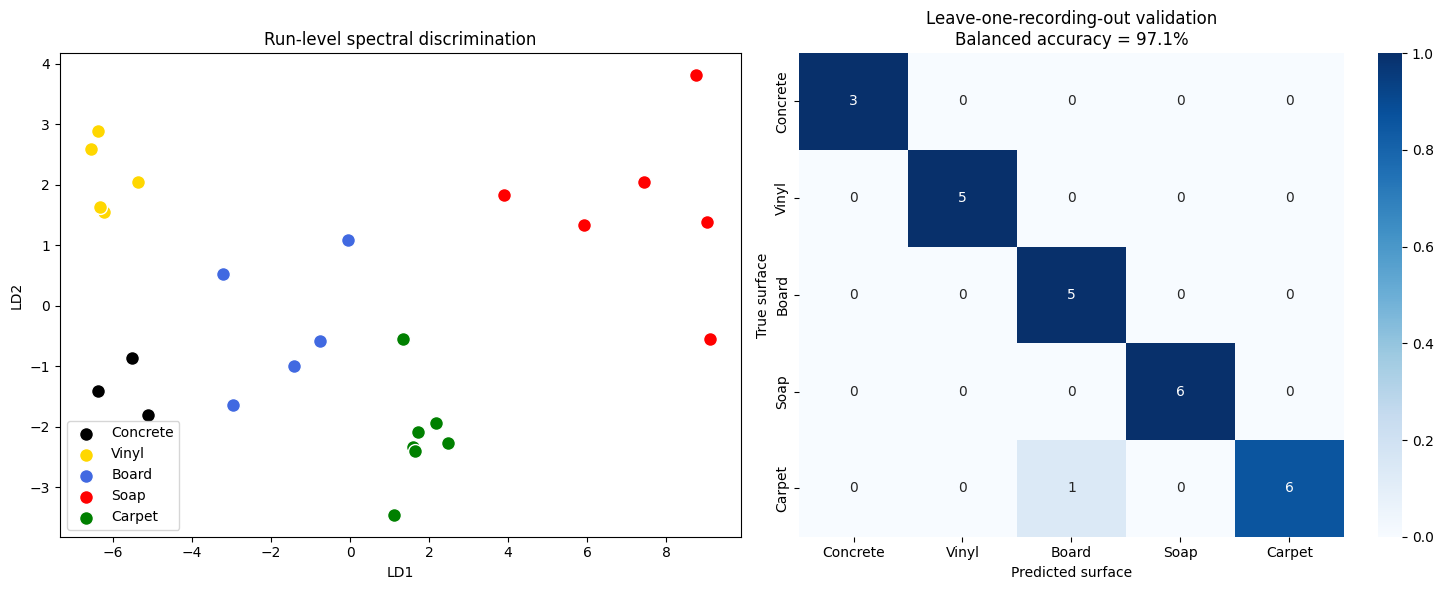

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import (
    LeaveOneOut,
    RepeatedStratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
)

NPZ_FILE = "Surface_spectral_analysis.npz"

surfaces = [
    "Concrete",
    "Vinyl",
    "Board",
    "Soap",
    "Carpet",
]

colors = {
    "Concrete": "black",
    "Vinyl": "gold",
    "Board": "royalblue",
    "Soap": "red",
    "Carpet": "green",
}

FREQ_MIN = 3.5
FREQ_MAX = 9.5
MIN_SEGMENTS = 4

data = np.load(
    NPZ_FILE,
    allow_pickle=True
)["data"].item()


def extract_features(frequency, error_psd):

    frequency = np.asarray(frequency, dtype=float)
    error_psd = np.asarray(error_psd, dtype=float)

    valid = (
        np.isfinite(frequency)
        & np.isfinite(error_psd)
        & (error_psd > 0)
        & (frequency >= FREQ_MIN)
        & (frequency <= FREQ_MAX)
    )

    frequency = frequency[valid]
    error_psd = error_psd[valid]

    if len(frequency) < 3:
        return None

    order = np.argsort(frequency)
    frequency = frequency[order]
    error_psd = error_psd[order]

    power = np.trapezoid(
        error_psd,
        frequency
    )

    energy_db = 10 * np.log10(power)

    centroid = (
        np.trapezoid(
            frequency * error_psd,
            frequency
        )
        / power
    )

    slope = np.polyfit(
        frequency,
        10 * np.log10(error_psd),
        1
    )[0]

    return energy_db, centroid, slope


rows = []

for surface in surfaces:

    surface_data = data[surface]

    number_of_recordings = len(
        surface_data["down_spectral_segments_used"]
    )

    for recording in range(number_of_recordings):

        down_count = int(
            surface_data[
                "down_spectral_segments_used"
            ][recording]
        )

        up_count = int(
            surface_data[
                "up_spectral_segments_used"
            ][recording]
        )

        if min(down_count, up_count) < MIN_SEGMENTS:
            continue

        row = {
            "Surface": surface,
            "Recording": recording,
        }

        recording_is_valid = True

        for direction in ["down", "up"]:

            result = extract_features(
                surface_data[
                    f"{direction}_spectral_frequency"
                ][recording],
                surface_data[
                    f"{direction}_mean_error_psd"
                ][recording],
            )

            if result is None:
                recording_is_valid = False
                break

            energy, centroid, slope = result

            row[f"{direction}_energy"] = energy
            row[f"{direction}_centroid"] = centroid
            row[f"{direction}_slope"] = slope

        if recording_is_valid:
            rows.append(row)


df = pd.DataFrame(rows)

features = [
    "down_energy",
    "up_energy",
    "down_centroid",
    "up_centroid",
    "down_slope",
    "up_slope",
]

X = df[features]
y = df["Surface"]


# ------------------------------------------------------------
# Honest recording-level classification
# ------------------------------------------------------------

classifier = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            max_iter=5000,
            class_weight="balanced"
        )
    ),
])

predictions = cross_val_predict(
    classifier,
    X,
    y,
    cv=LeaveOneOut()
)

balanced_accuracy = balanced_accuracy_score(
    y,
    predictions
)

confusion = confusion_matrix(
    y,
    predictions,
    labels=surfaces
)

repeated_cv = RepeatedStratifiedKFold(
    n_splits=3,
    n_repeats=100,
    random_state=718
)

scores = cross_val_score(
    classifier,
    X,
    y,
    cv=repeated_cv,
    scoring="balanced_accuracy"
)

print(
    f"Leave-one-recording-out balanced accuracy: "
    f"{balanced_accuracy:.1%}"
)

print(
    f"Repeated three-fold balanced accuracy: "
    f"{scores.mean():.1%} ± {scores.std():.1%}"
)


# ------------------------------------------------------------
# Six-feature discriminant map
# ------------------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lda = LinearDiscriminantAnalysis(
    solver="eigen",
    shrinkage="auto",
    n_components=2
)

coordinates = lda.fit_transform(
    X_scaled,
    y
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

for surface in surfaces:

    mask = y.to_numpy() == surface

    axes[0].scatter(
        coordinates[mask, 0],
        coordinates[mask, 1],
        s=100,
        color=colors[surface],
        edgecolor="white",
        label=surface
    )

axes[0].set_xlabel("LD1")
axes[0].set_ylabel("LD2")
axes[0].set_title("Run-level spectral discrimination")
axes[0].legend()


# ------------------------------------------------------------
# Cross-validated confusion matrix
# ------------------------------------------------------------

row_fraction = (
    confusion
    / confusion.sum(axis=1, keepdims=True)
)

sns.heatmap(
    row_fraction,
    annot=confusion,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=surfaces,
    yticklabels=surfaces,
    ax=axes[1]
)

axes[1].set_xlabel("Predicted surface")
axes[1].set_ylabel("True surface")
axes[1].set_title(
    f"Leave-one-recording-out validation\n"
    f"Balanced accuracy = {balanced_accuracy:.1%}"
)

plt.tight_layout()
plt.show()

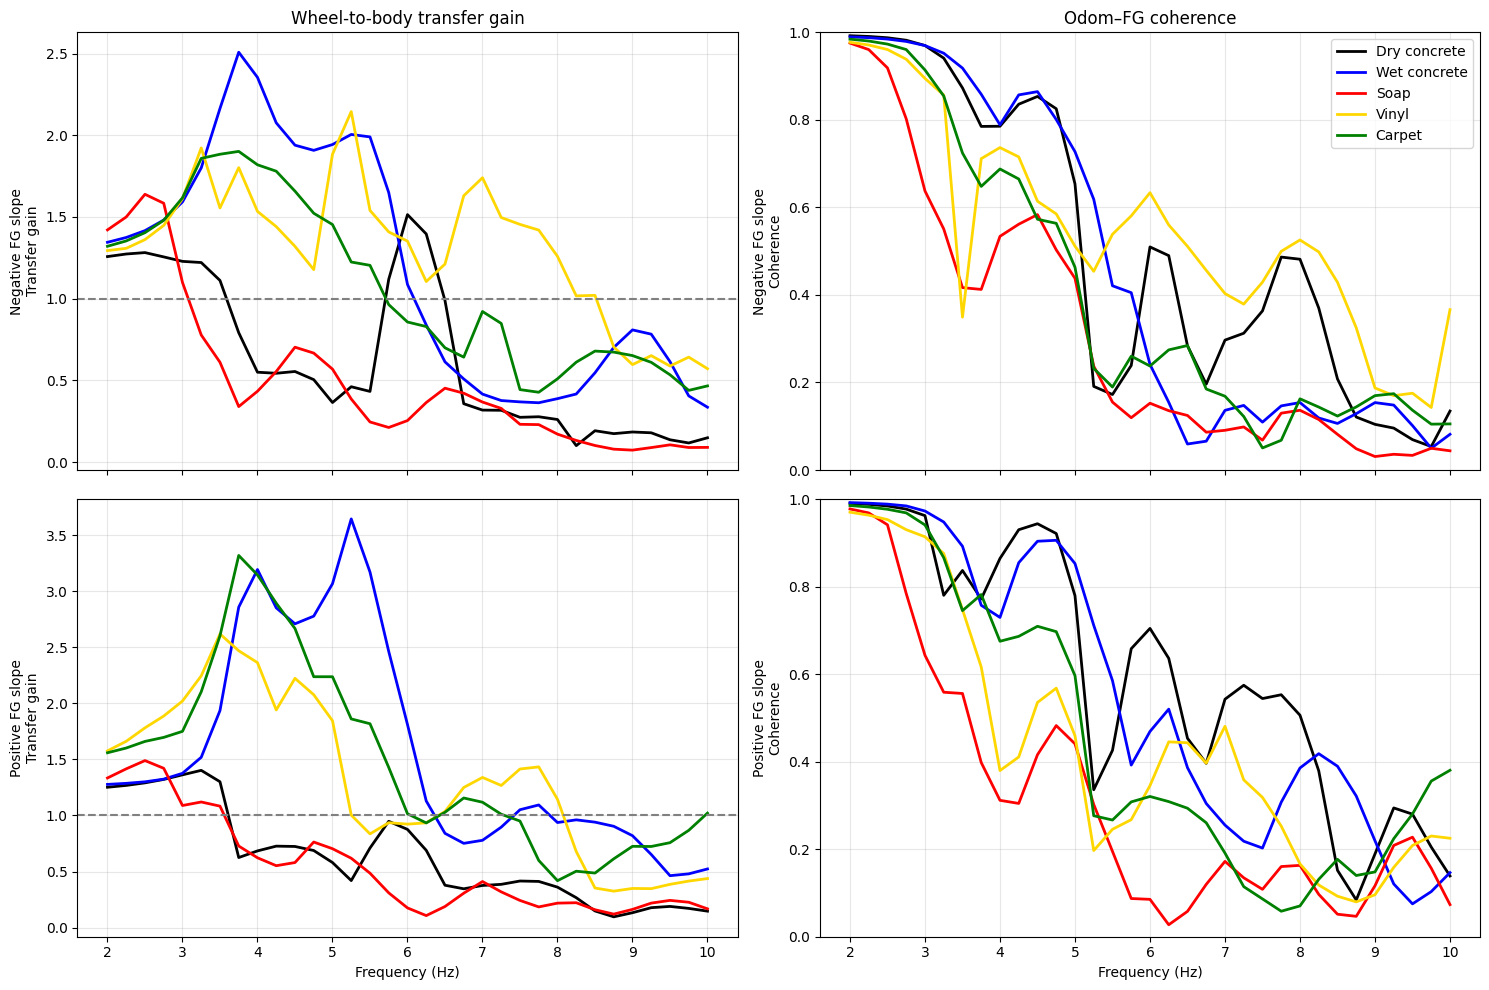

In [3]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
    sharex=True
)

for row, (
    direction,
    direction_title
) in enumerate(directions.items()):

    for surface, category_key in (
        surface_2s.items()
    ):

        frequency = np.asarray(
            data[category_key][
                f"{direction}_spectral_frequency"
            ][0],
            dtype=float
        )

        coherence_spectra = np.asarray(
            data[category_key][
                f"{direction}_coherence_spectrum"
            ],
            dtype=float
        )

        gain_spectra = np.asarray(
            data[category_key][
                f"{direction}_transfer_gain_spectrum"
            ],
            dtype=float
        )

        axes[row, 0].plot(
            frequency,
            np.nanmedian(
                gain_spectra,
                axis=0
            ),
            color=surface_colors[surface],
            linewidth=2,
            label=surface
        )

        axes[row, 1].plot(
            frequency,
            np.nanmedian(
                coherence_spectra,
                axis=0
            ),
            color=surface_colors[surface],
            linewidth=2,
            label=surface
        )

    axes[row, 0].axhline(
        1.0,
        color="gray",
        linestyle="--"
    )

    axes[row, 0].set_ylabel(
        f"{direction_title}\nTransfer gain"
    )

    axes[row, 1].set_ylabel(
        f"{direction_title}\nCoherence"
    )

    axes[row, 1].set_ylim(0, 1)

    for col in range(2):
        axes[row, col].grid(
            True,
            alpha=0.3
        )

axes[0, 0].set_title(
    "Wheel-to-body transfer gain"
)

axes[0, 1].set_title(
    "Odom–FG coherence"
)

axes[1, 0].set_xlabel("Frequency (Hz)")
axes[1, 1].set_xlabel("Frequency (Hz)")

axes[0, 1].legend()

plt.tight_layout()
plt.show()


Surface traction-response summary
 Surface  Recordings  Median reversal frequency (Hz)  FFT phase delay (s) FFT delay IQR (s)  Zero-crossing delay (s) Zero-crossing IQR (s)  Body/odom gain  Aligned normalized RMS
    Soap           6                           0.345                0.349       0.331–0.361                    0.494           0.483–0.500           1.205                   0.369
   Board           5                           0.500                0.157       0.145–0.157                    0.265           0.257–0.267           1.302                   0.393
Concrete           4                           0.167                0.120       0.111–0.132                    0.215           0.207–0.223           1.188                   0.243
   Vinyl           6                           0.250                0.116       0.105–0.125                    0.197           0.194–0.199           1.182                   0.268
  Carpet           8                           0.333                0.

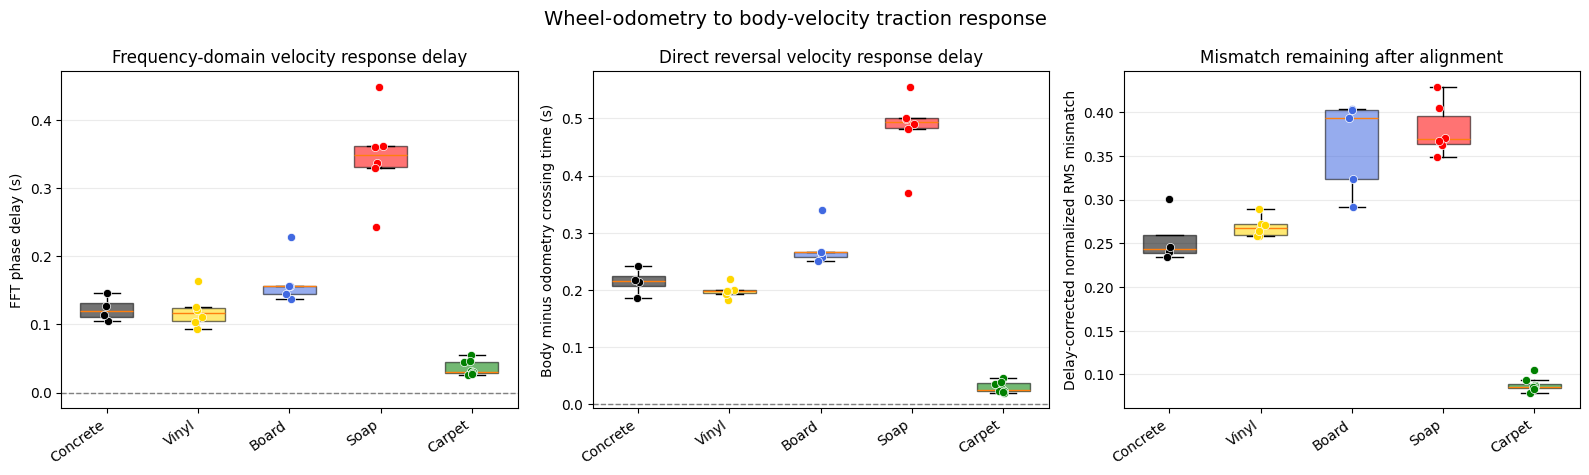

In [1]:
"""Surface traction-response analysis from Surface_spectral_analysis.npz.

This script treats one complete recording as one independent observation and
calculates:

1. Direct body-versus-odometry zero-crossing delay at each velocity reversal.
2. FFT/transfer-function phase delay at the commanded reversal frequency.
3. Body/odometry transfer gain at that frequency.
4. Normalized RMS mismatch after compensating for the estimated phase delay.

Longer delay means that body velocity catches up to wheel odometry more slowly.
It is a traction-response indicator, not by itself a coefficient of friction.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# -----------------------------------------------------------------------------
# Settings
# -----------------------------------------------------------------------------

NPZ_FILE = Path("Surface_spectral_analysis.npz")

SURFACES = [
    "Concrete",
    "Vinyl",
    "Board",
    "Soap",
    "Carpet",
]

COLORS = {
    "Concrete": "black",
    "Vinyl": "gold",
    "Board": "royalblue",
    "Soap": "red",
    "Carpet": "green",
}

# Reject an event only when the body crossing is implausibly far from the
# corresponding odometry crossing. Adjust if your maneuver is slower.
MIN_VALID_DELAY_S = -0.10
MAX_VALID_DELAY_S = 1.20


# -----------------------------------------------------------------------------
# Helpers for recovering the raw odometry/relative-velocity alignment
# -----------------------------------------------------------------------------

def _find_subsequence(full, sub, rtol=1e-10, atol=1e-10):
    """Return the first index at which `sub` occurs in `full`, else None."""

    full = np.asarray(full, dtype=float).ravel()
    sub = np.asarray(sub, dtype=float).ravel()

    if len(sub) == 0 or len(sub) > len(full):
        return None

    possible = np.flatnonzero(
        np.isclose(
            full[: len(full) - len(sub) + 1],
            sub[0],
            rtol=rtol,
            atol=atol,
        )
    )

    for index in possible:
        if np.allclose(
            full[index : index + len(sub)],
            sub,
            rtol=rtol,
            atol=atol,
            equal_nan=True,
        ):
            return int(index)

    return None


def _map_valid_error_segments(surface_data, direction):
    """Map each saved error segment to its matching odom/FG segment index."""

    odom_segments = surface_data[f"{direction}_odom_segments"]
    fg_segments = surface_data[f"{direction}_fg_segments"]
    error_segments = surface_data[f"{direction}_vrel_segments"]

    mapping = []
    next_original_index = 0

    for error_index, error in enumerate(error_segments):
        error = np.asarray(error, dtype=float).ravel()
        matched_index = None

        for original_index in range(
            next_original_index,
            len(odom_segments),
        ):
            odom = np.asarray(
                odom_segments[original_index],
                dtype=float,
            ).ravel()
            fg = np.asarray(
                fg_segments[original_index],
                dtype=float,
            ).ravel()

            if not (
                len(odom) == len(fg) == len(error)
            ):
                continue

            if np.allclose(
                odom - fg,
                error,
                rtol=1e-10,
                atol=1e-10,
                equal_nan=True,
            ):
                matched_index = original_index
                break

        if matched_index is not None:
            mapping.append((error_index, matched_index))
            next_original_index = matched_index + 1

    return mapping


def infer_raw_offsets(surface_data):
    """Infer where raw v_rel begins relative to raw v_odom for each run."""

    candidate_offsets = {}

    for direction in ("down", "up"):
        counts = np.asarray(
            surface_data[f"{direction}_spectral_segments_used"],
            dtype=int,
        )
        cumulative = np.cumsum(np.r_[0, counts])

        odom_segments = surface_data[f"{direction}_odom_segments"]
        error_segments = surface_data[f"{direction}_vrel_segments"]

        for error_index, original_index in _map_valid_error_segments(
            surface_data,
            direction,
        ):
            run_index = int(
                np.searchsorted(
                    cumulative[1:],
                    original_index,
                    side="right",
                )
            )

            if run_index >= len(surface_data["v_odom"]):
                continue

            raw_odom = np.asarray(
                surface_data["v_odom"][run_index],
                dtype=float,
            )[:, 0]
            raw_error = np.asarray(
                surface_data["v_rel"][run_index],
                dtype=float,
            )

            odom_location = _find_subsequence(
                raw_odom,
                odom_segments[original_index],
            )
            error_location = _find_subsequence(
                raw_error,
                error_segments[error_index],
            )

            if odom_location is None or error_location is None:
                continue

            candidate_offsets.setdefault(run_index, []).append(
                odom_location - error_location
            )

    return {
        run_index: int(np.median(offsets))
        for run_index, offsets in candidate_offsets.items()
    }


def recover_run(surface_data, run_index, odom_offset):
    """Return aligned time, odometry velocity, and FG/body velocity."""

    all_time = np.asarray(
        surface_data["t_odom_abs"][run_index],
        dtype=float,
    ).ravel()
    all_odom = np.asarray(
        surface_data["v_odom"][run_index],
        dtype=float,
    )[:, 0]
    relative_velocity = np.asarray(
        surface_data["v_rel"][run_index],
        dtype=float,
    ).ravel()

    n = min(
        len(relative_velocity),
        len(all_odom) - odom_offset,
        len(all_time) - odom_offset,
    )

    time = all_time[odom_offset : odom_offset + n]
    odom = all_odom[odom_offset : odom_offset + n]
    relative_velocity = relative_velocity[:n]

    # The saved definition is v_rel = v_odom - v_FG.
    body = odom - relative_velocity

    valid = (
        np.isfinite(time)
        & np.isfinite(odom)
        & np.isfinite(body)
    )

    time = time[valid]
    odom = odom[valid]
    body = body[valid]

    order = np.argsort(time)
    time = time[order]
    odom = odom[order]
    body = body[order]

    time, unique_indices = np.unique(
        time,
        return_index=True,
    )

    return (
        time,
        odom[unique_indices],
        body[unique_indices],
    )


# -----------------------------------------------------------------------------
# Delay and transfer-function calculations
# -----------------------------------------------------------------------------

def crossing_time(time, velocity, start, stop, new_sign):
    """Linearly interpolate the requested zero crossing within a window."""

    indices = np.flatnonzero(
        (time >= start)
        & (time < stop)
        & np.isfinite(velocity)
    )

    if len(indices) < 2:
        return np.nan

    for left, right in zip(indices[:-1], indices[1:]):
        if new_sign < 0:
            crossed = velocity[left] > 0 and velocity[right] <= 0
        else:
            crossed = velocity[left] < 0 and velocity[right] >= 0

        if not crossed:
            continue

        dv = velocity[right] - velocity[left]

        if dv == 0:
            return float(time[right])

        return float(
            time[left]
            - velocity[left]
            * (time[right] - time[left])
            / dv
        )

    return np.nan


def exact_frequency_coefficient(time, signal, frequency):
    """Sinusoidal least-squares coefficient at one exact frequency."""

    local_time = time - time[0]
    omega_time = 2.0 * np.pi * frequency * local_time

    # Intercept and trend prevent slow drift from biasing the phase.
    design = np.column_stack(
        [
            np.ones_like(local_time),
            local_time,
            np.cos(omega_time),
            np.sin(omega_time),
        ]
    )

    coefficients = np.linalg.lstsq(
        design,
        signal,
        rcond=None,
    )[0]

    # If x = A cos(wt) + B sin(wt), A - iB is its complex coefficient.
    return coefficients[2] - 1j * coefficients[3]


def normalized_aligned_rms(time, odom, body, delay, start, stop):
    """Mismatch after advancing the lagged body signal by `delay` seconds."""

    evaluation = (
        (time >= start)
        & (time <= stop)
        & (time + delay >= time[0])
        & (time + delay <= time[-1])
    )

    if np.count_nonzero(evaluation) < 8:
        return np.nan

    t_eval = time[evaluation]
    odom_eval = odom[evaluation]

    # If body(t) approximately equals odom(t-delay), compare odom(t) with
    # body(t+delay) to remove the estimated lag.
    aligned_body = np.interp(
        t_eval + delay,
        time,
        body,
    )

    scale = np.sqrt(
        np.mean(
            (odom_eval - np.mean(odom_eval)) ** 2
        )
    )

    if not np.isfinite(scale) or scale <= 0:
        return np.nan

    return float(
        np.sqrt(
            np.mean((odom_eval - aligned_body) ** 2)
        )
        / scale
    )


def analyze_recording(
    surface,
    surface_data,
    run_index,
    odom_offset,
):
    """Calculate run-level FFT metrics and event-level crossing delays."""

    command = np.asarray(
        surface_data["cmd_vel"][run_index],
        dtype=float,
    )
    command_time = np.asarray(
        surface_data["t_cmd"][run_index],
        dtype=float,
    )

    # Some saved runs contain no command trace and are represented by scalars.
    if (
        command.ndim == 0
        or command_time.ndim == 0
        or len(command) < 4
    ):
        return None, []

    time, odom, body = recover_run(
        surface_data,
        run_index,
        odom_offset,
    )

    # A true reversal changes directly between positive and negative command.
    changes = np.flatnonzero(
        command[1:] * command[:-1] < 0
    ) + 1

    if len(changes) < 2:
        return None, []

    half_period = float(
        np.median(np.diff(command_time[changes]))
    )
    reversal_frequency = 1.0 / (2.0 * half_period)

    analysis_start = max(
        command_time[changes[0]],
        time[0],
    )
    analysis_stop = min(
        command_time[changes[-1]],
        time[-1],
    )

    analysis_mask = (
        (time >= analysis_start)
        & (time <= analysis_stop)
    )

    if np.count_nonzero(analysis_mask) < 20:
        return None, []

    odom_fft = exact_frequency_coefficient(
        time[analysis_mask],
        odom[analysis_mask],
        reversal_frequency,
    )
    body_fft = exact_frequency_coefficient(
        time[analysis_mask],
        body[analysis_mask],
        reversal_frequency,
    )

    if abs(odom_fft) <= np.finfo(float).eps:
        return None, []

    transfer = body_fft / odom_fft
    phase_radians = float(np.angle(transfer))
    phase_delay = -phase_radians / (
        2.0 * np.pi * reversal_frequency
    )

    # Put the delay on the principal physically interpretable branch.
    period = 1.0 / reversal_frequency

    while phase_delay > period / 2.0:
        phase_delay -= period

    while phase_delay < -period / 2.0:
        phase_delay += period

    aligned_rms = normalized_aligned_rms(
        time,
        odom,
        body,
        phase_delay,
        analysis_start,
        analysis_stop,
    )

    event_rows = []

    for change_number, change_index in enumerate(changes):
        event_start = float(command_time[change_index])

        if change_number + 1 < len(changes):
            next_reversal = float(
                command_time[changes[change_number + 1]]
            )
        else:
            next_reversal = min(
                float(command_time[-1]) + 0.3,
                float(time[-1]),
            )

        # Never let one crossing search spill into the next command reversal.
        event_stop = min(
            next_reversal,
            event_start + MAX_VALID_DELAY_S + 0.3,
            float(time[-1]),
        )

        new_sign = float(np.sign(command[change_index]))

        odom_crossing = crossing_time(
            time,
            odom,
            event_start,
            event_stop,
            new_sign,
        )
        body_crossing = crossing_time(
            time,
            body,
            event_start,
            event_stop,
            new_sign,
        )

        delay = body_crossing - odom_crossing

        if not (
            np.isfinite(delay)
            and MIN_VALID_DELAY_S <= delay <= MAX_VALID_DELAY_S
        ):
            continue

        event_rows.append(
            {
                "surface": surface,
                "run": run_index,
                "direction": (
                    "Positive" if new_sign > 0 else "Negative"
                ),
                "zero_cross_delay_s": float(delay),
            }
        )

    run_zero_cross_delay = (
        float(
            np.median(
                [row["zero_cross_delay_s"] for row in event_rows]
            )
        )
        if event_rows
        else np.nan
    )

    run_row = {
        "surface": surface,
        "run": run_index,
        "reversal_frequency_Hz": reversal_frequency,
        "phase_delay_s": phase_delay,
        "zero_cross_delay_s": run_zero_cross_delay,
        "body_to_odom_gain": float(abs(transfer)),
        "aligned_normalized_RMS": aligned_rms,
        "reversals_used": len(event_rows),
    }

    return run_row, event_rows


def median_iqr(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan, np.nan

    return (
        float(np.median(values)),
        float(np.percentile(values, 25)),
        float(np.percentile(values, 75)),
    )


def summarize_runs(run_results):
    rows = []

    for surface in SURFACES:
        group = run_results[
            run_results["surface"] == surface
        ]

        if group.empty:
            continue

        phase, phase_q1, phase_q3 = median_iqr(
            group["phase_delay_s"]
        )
        crossing, crossing_q1, crossing_q3 = median_iqr(
            group["zero_cross_delay_s"]
        )

        rows.append(
            {
                "Surface": surface,
                "Recordings": len(group),
                "Median reversal frequency (Hz)": np.median(
                    group["reversal_frequency_Hz"]
                ),
                "FFT phase delay (s)": phase,
                "FFT delay IQR (s)": (
                    f"{phase_q1:.3f}–{phase_q3:.3f}"
                ),
                "Zero-crossing delay (s)": crossing,
                "Zero-crossing IQR (s)": (
                    f"{crossing_q1:.3f}–{crossing_q3:.3f}"
                ),
                "Body/odom gain": np.median(
                    group["body_to_odom_gain"]
                ),
                "Aligned normalized RMS": np.median(
                    group["aligned_normalized_RMS"]
                ),
            }
        )

    return pd.DataFrame(rows).sort_values(
        "Zero-crossing delay (s)",
        ascending=False,
    )


def colored_boxplot(ax, run_results, column, ylabel, baseline=None):
    values = [
        run_results.loc[
            run_results["surface"] == surface,
            column,
        ].dropna().to_numpy()
        for surface in SURFACES
    ]

    boxplot = ax.boxplot(
        values,
        patch_artist=True,
        showfliers=False,
        widths=0.58,
    )

    for patch, surface in zip(boxplot["boxes"], SURFACES):
        patch.set_facecolor(COLORS[surface])
        patch.set_alpha(0.55)

    rng = np.random.default_rng(7)

    for position, (surface, surface_values) in enumerate(
        zip(SURFACES, values),
        start=1,
    ):
        jitter = rng.normal(0.0, 0.035, len(surface_values))
        ax.scatter(
            position + jitter,
            surface_values,
            color=COLORS[surface],
            edgecolor="white",
            linewidth=0.5,
            s=35,
            zorder=3,
        )

    if baseline is not None:
        ax.axhline(
            baseline,
            color="gray",
            linestyle="--",
            linewidth=1,
        )

    ax.set_xticks(range(1, len(SURFACES) + 1))
    ax.set_xticklabels(SURFACES, rotation=35, ha="right")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)


# -----------------------------------------------------------------------------
# Run the analysis
# -----------------------------------------------------------------------------

if not NPZ_FILE.exists():
    fallback = Path("upload") / NPZ_FILE.name

    if fallback.exists():
        NPZ_FILE = fallback
    else:
        raise FileNotFoundError(
            f"Could not find {NPZ_FILE.name} in the current directory."
        )

data = np.load(
    NPZ_FILE,
    allow_pickle=True,
)["data"].item()

SURFACES = [surface for surface in SURFACES if surface in data]

run_rows = []
event_rows = []

for surface in SURFACES:
    surface_data = data[surface]
    offsets = infer_raw_offsets(surface_data)

    for run_index, odom_offset in sorted(offsets.items()):
        run_row, recording_events = analyze_recording(
            surface,
            surface_data,
            run_index,
            odom_offset,
        )

        if run_row is not None:
            run_rows.append(run_row)
            event_rows.extend(recording_events)

run_results = pd.DataFrame(run_rows)
event_results = pd.DataFrame(event_rows)

if run_results.empty:
    raise RuntimeError(
        "No valid recordings were found for the catch-up analysis."
    )

summary = summarize_runs(run_results)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

print("\nSurface traction-response summary")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

print("\nLag-based order (longest to shortest body catch-up delay):")
print(" > ".join(summary["Surface"]))

print(
    "\nInterpretation: longer delay means slower body response. "
    "It does not, by itself, prove a lower coefficient of friction."
)


# -----------------------------------------------------------------------------
# Diagnostic plots: each point is one complete recording
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.8),
)

colored_boxplot(
    axes[0],
    run_results,
    "phase_delay_s",
    "FFT phase delay (s)",
    baseline=0.0,
)
axes[0].set_title("Frequency-domain velocity response delay")

colored_boxplot(
    axes[1],
    run_results,
    "zero_cross_delay_s",
    "Body minus odometry crossing time (s)",
    baseline=0.0,
)
axes[1].set_title("Direct reversal velocity response delay")

colored_boxplot(
    axes[2],
    run_results,
    "aligned_normalized_RMS",
    "Delay-corrected normalized RMS mismatch",
)
axes[2].set_title("Mismatch remaining after alignment")

fig.suptitle(
    "Wheel-odometry to body-velocity traction response",
    fontsize=14,
)
fig.tight_layout()
plt.show()


# Useful notebook variables:
#   run_results   -> one row per independent recording
#   event_results -> one row per valid direction reversal
#   summary       -> surface medians and IQRs



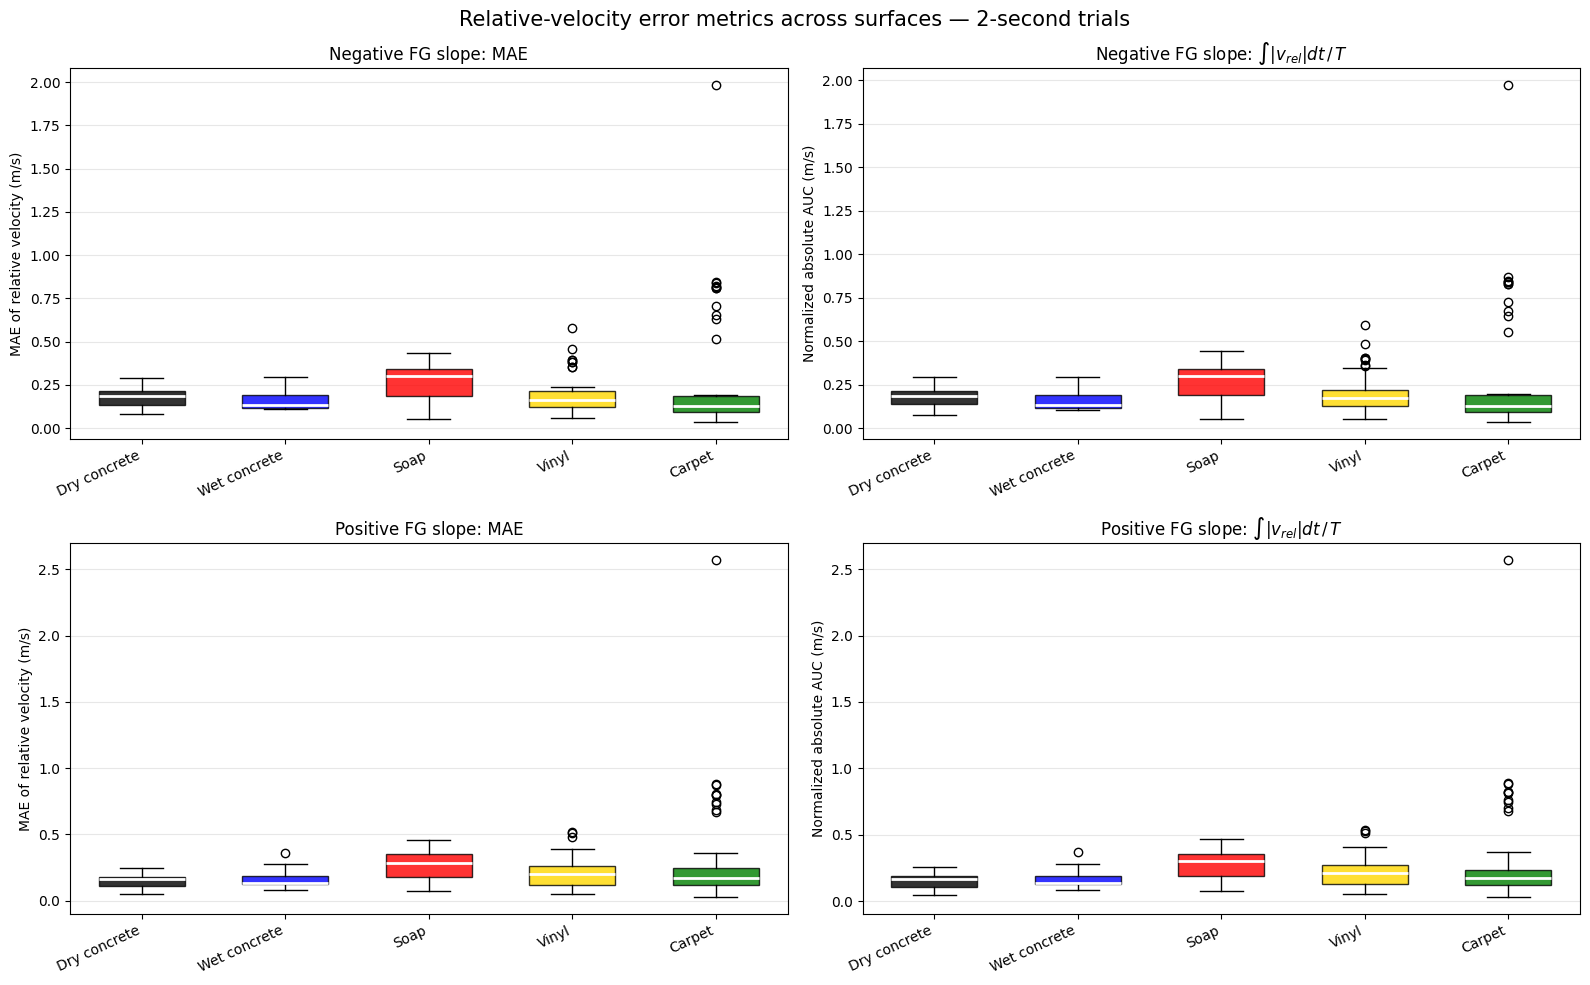

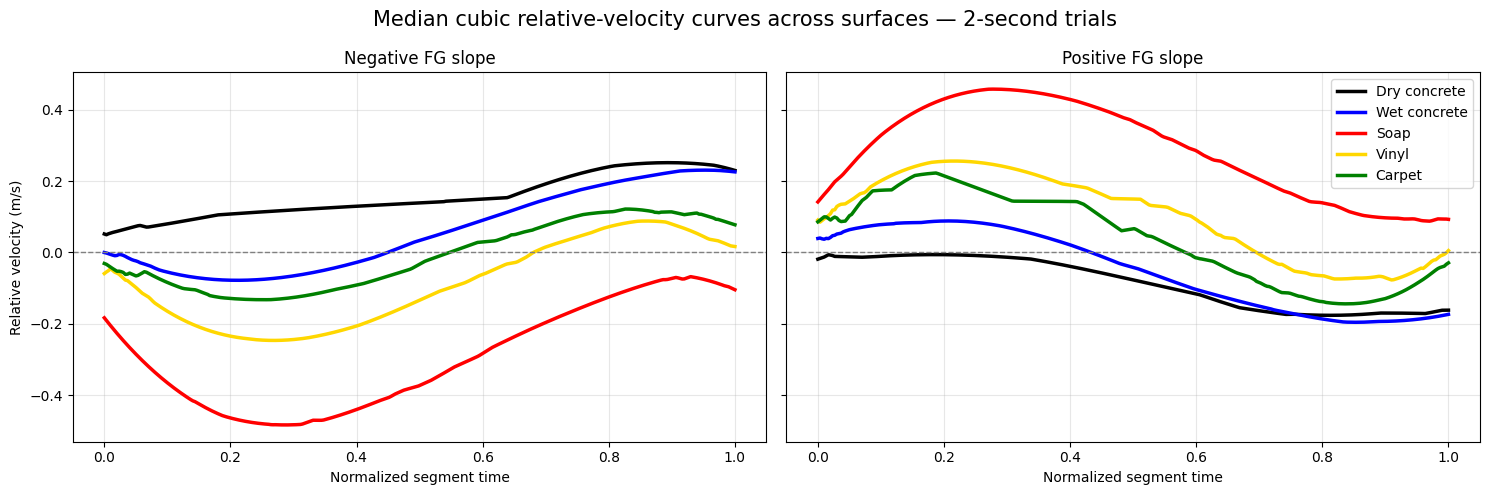

In [4]:
import numpy as np
import matplotlib.pyplot as plt

NPZ_FILE = "Concrete_different_times1.npz"

data = np.load(NPZ_FILE, allow_pickle=True)["data"].item()

# Change only these keys if your category names differ
surfaces = {
    "Dry concrete": "Concrete_2s",
    "Wet concrete": "Concrete_wet_2s",
    "Soap": "Soap_2s",
    "Vinyl": "Vinyl_2s",
    "Carpet": "Carpet_2s",
}

colors = {
    "Dry concrete": "black",
    "Wet concrete": "blue",
    "Soap": "red",
    "Vinyl": "gold",
    "Carpet": "green",
}


# ============================================================
# 1. MAE AND NORMALIZED ABSOLUTE AUC
# ============================================================

directions = {
    "down": "Negative FG slope",
    "up": "Positive FG slope",
}

metrics = {
    "mae": ("MAE of relative velocity (m/s)", "MAE"),
    "auc_abs": (
        "Normalized absolute AUC (m/s)",
        r"$\int |v_{rel}|dt\,/\,T$",
    ),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

surface_names = list(surfaces.keys())
positions = np.arange(1, len(surface_names) + 1)

for row, (direction, direction_title) in enumerate(directions.items()):
    for col, (metric, (ylabel, metric_title)) in enumerate(metrics.items()):

        ax = axes[row, col]
        values_by_surface = []

        for surface in surface_names:
            category = surfaces[surface]

            values = np.asarray(
                data[category][f"{direction}_{metric}"],
                dtype=float
            ).ravel()

            values = values[np.isfinite(values)]
            values_by_surface.append(values)

        bp = ax.boxplot(
            values_by_surface,
            positions=positions,
            widths=0.6,
            patch_artist=True,
            showfliers=True,
            medianprops={
                "color": "white",
                "linewidth": 2
            },
        )

        for box, surface in zip(bp["boxes"], surface_names):
            box.set_facecolor(colors[surface])
            box.set_alpha(0.8)

        ax.set_xticks(positions)
        ax.set_xticklabels(surface_names, rotation=25, ha="right")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{direction_title}: {metric_title}")
        ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Relative-velocity error metrics across surfaces — 2-second trials",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ============================================================
# 2. MEDIAN CUBIC POLYNOMIAL CURVES
# ============================================================

tau = np.linspace(0.0, 1.0, 300)


def get_polynomial_curves(category, direction):
    """
    Evaluate every stored cubic polynomial on the same normalized
    time axis.

    Stored coefficients are assumed to use np.polyfit/np.polyval order.
    """
    coeffs = np.asarray(
        data[category][f"{direction}_poly_coeffs"],
        dtype=float
    )

    curves = np.array([
        np.polyval(coeff, tau)
        for coeff in coeffs
    ])

    return curves


fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

for ax, (direction, direction_title) in zip(axes, directions.items()):

    for surface, category in surfaces.items():

        curves = get_polynomial_curves(category, direction)

        # Pointwise median across all polynomial curves
        median_curve = np.median(curves, axis=0)

        ax.plot(
            tau,
            median_curve,
            color=colors[surface],
            linewidth=2.5,
            label=surface
        )

    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(direction_title)
    ax.set_xlabel("Normalized segment time")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Relative velocity (m/s)")
axes[1].legend(loc="best")

fig.suptitle(
    "Median cubic relative-velocity curves across surfaces — 2-second trials",
    fontsize=15
)

plt.tight_layout()
plt.show()

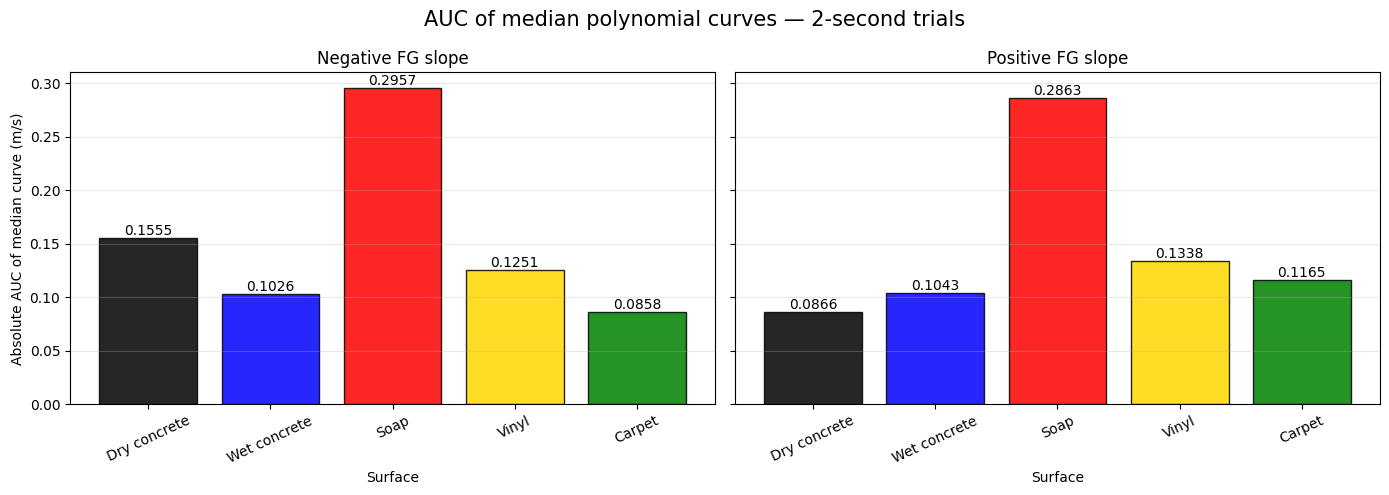


Negative FG slope
Dry concrete   : 0.155523
Wet concrete   : 0.102639
Soap           : 0.295653
Vinyl          : 0.125093
Carpet         : 0.085826

Positive FG slope
Dry concrete   : 0.086644
Wet concrete   : 0.104292
Soap           : 0.286340
Vinyl          : 0.133753
Carpet         : 0.116498


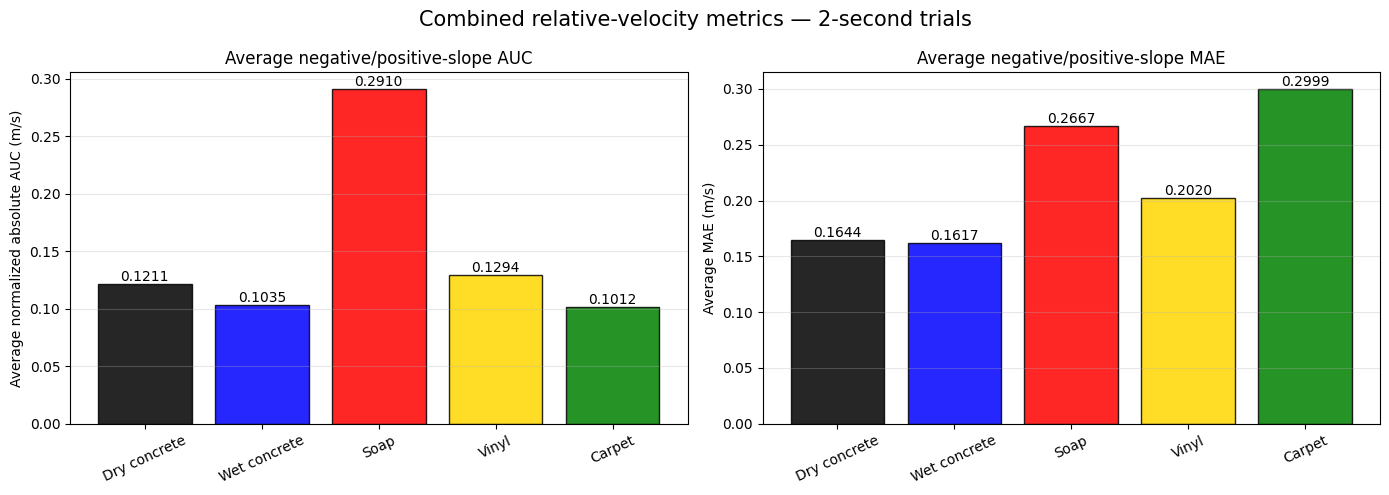

Surface             Average AUC     Average MAE
------------------------------------------------
Dry concrete           0.121083        0.164385
Wet concrete           0.103465        0.161735
Soap                   0.290997        0.266724
Vinyl                  0.129423        0.202042
Carpet                 0.101162        0.299870


In [8]:
# ============================================================
# ABSOLUTE AUC OF MEDIAN POLYNOMIAL CURVES
# ============================================================

tau = np.linspace(0, 1, 300)
surface_names = list(surfaces.keys())

median_poly_auc = {
    "down": {},
    "up": {}
}

for direction in ["down", "up"]:
    for surface, category in surfaces.items():

        coeffs = np.asarray(
            data[category][f"{direction}_poly_coeffs"],
            dtype=float
        )

        # Evaluate every stored polynomial on normalized time
        curves = np.array([
            np.polyval(coeff, tau)
            for coeff in coeffs
        ])

        # Pointwise median curve
        median_curve = np.median(curves, axis=0)

        # Absolute normalized AUC
        median_poly_auc[direction][surface] = np.trapezoid(
            np.abs(median_curve),
            tau
        )


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

direction_titles = {
    "down": "Negative FG slope",
    "up": "Positive FG slope"
}

for ax, direction in zip(axes, ["down", "up"]):

    values = [
        median_poly_auc[direction][surface]
        for surface in surface_names
    ]

    bars = ax.bar(
        surface_names,
        values,
        color=[colors[surface] for surface in surface_names],
        edgecolor="black",
        alpha=0.85
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

    ax.set_title(direction_titles[direction])
    ax.set_xlabel("Surface")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Absolute AUC of median curve (m/s)")

fig.suptitle(
    "AUC of median polynomial curves — 2-second trials",
    fontsize=15
)

plt.tight_layout()
plt.show()


# Print exact values
for direction in ["down", "up"]:
    print(f"\n{direction_titles[direction]}")

    for surface in surface_names:
        print(
            f"{surface:15s}: "
            f"{median_poly_auc[direction][surface]:.6f}"
        )
# ============================================================
# AVERAGE UP/DOWN AUC AND MAE FOR EACH SURFACE
# ============================================================

average_auc = {}
average_mae = {}

for surface, category in surfaces.items():

    # Average of the two median-polynomial AUC values
    average_auc[surface] = 0.5 * (
        median_poly_auc["down"][surface]
        + median_poly_auc["up"][surface]
    )

    # Mean segment MAE within each direction
    down_mae = np.asarray(data[category]["down_mae"], dtype=float)
    up_mae = np.asarray(data[category]["up_mae"], dtype=float)

    down_mae = down_mae[np.isfinite(down_mae)]
    up_mae = up_mae[np.isfinite(up_mae)]

    # Give the two directions equal weight
    average_mae[surface] = 0.5 * (
        np.mean(down_mae) + np.mean(up_mae)
    )


# ============================================================
# Plot
# ============================================================

surface_names = list(surfaces.keys())
bar_colors = [colors[surface] for surface in surface_names]

auc_values = [average_auc[surface] for surface in surface_names]
mae_values = [average_mae[surface] for surface in surface_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average AUC
bars = axes[0].bar(
    surface_names,
    auc_values,
    color=bar_colors,
    edgecolor="black",
    alpha=0.85
)

for bar, value in zip(bars, auc_values):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

axes[0].set_title("Average negative/positive-slope AUC")
axes[0].set_ylabel("Average normalized absolute AUC (m/s)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.3)


# Average MAE
bars = axes[1].bar(
    surface_names,
    mae_values,
    color=bar_colors,
    edgecolor="black",
    alpha=0.85
)

for bar, value in zip(bars, mae_values):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

axes[1].set_title("Average negative/positive-slope MAE")
axes[1].set_ylabel("Average MAE (m/s)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle(
    "Combined relative-velocity metrics — 2-second trials",
    fontsize=15
)

plt.tight_layout()
plt.show()


# Print values
print(f"{'Surface':15s} {'Average AUC':>15s} {'Average MAE':>15s}")
print("-" * 48)

for surface in surface_names:
    print(
        f"{surface:15s} "
        f"{average_auc[surface]:15.6f} "
        f"{average_mae[surface]:15.6f}"
    )

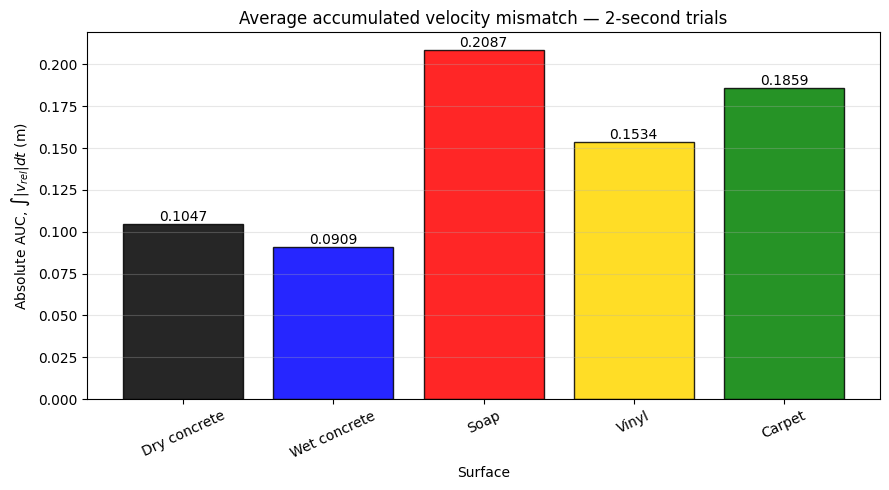

In [9]:
# ============================================================
# RECOVER UNNORMALIZED AUC FROM SAVED AUC AND DURATION
# ============================================================

average_raw_auc = {}
raw_auc_by_surface = {}

for surface, category in surfaces.items():

    down_auc_norm = np.asarray(
        data[category]["down_auc_abs"],
        dtype=float
    )

    up_auc_norm = np.asarray(
        data[category]["up_auc_abs"],
        dtype=float
    )

    down_duration = np.asarray(
        data[category]["down_durations"],
        dtype=float
    )

    up_duration = np.asarray(
        data[category]["up_durations"],
        dtype=float
    )

    # Undo the normalization
    down_auc_raw = down_auc_norm * down_duration
    up_auc_raw = up_auc_norm * up_duration

    raw_auc_by_surface[surface] = {
        "down": down_auc_raw,
        "up": up_auc_raw
    }

    # Equal weighting of negative and positive FG slopes
    average_raw_auc[surface] = 0.5 * (
        np.mean(down_auc_raw) +
        np.mean(up_auc_raw)
    )


# ============================================================
# PLOT
# ============================================================

surface_names = list(surfaces.keys())
values = [average_raw_auc[s] for s in surface_names]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    surface_names,
    values,
    color=[colors[s] for s in surface_names],
    edgecolor="black",
    alpha=0.85
)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.ylabel(r"Absolute AUC, $\int |v_{rel}|dt$ (m)")
plt.xlabel("Surface")
plt.title("Average accumulated velocity mismatch — 2-second trials")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()